In [ ]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import numpy as np


In [ ]:
!rm -rf colab_llm_utils

In [ ]:
!git clone -b multiaxial https://github.com/ravy101/colab_llm_utils.git

Cloning into 'colab_llm_utils'...
remote: Enumerating objects: 1561, done.
remote: Counting objects: 100% (83/83), done.
remote: Compressing objects: 100% (59/59), done.
remote: Total 1561 (delta 49), reused 55 (delta 24), pack-reused 1478 (from 2)
Receiving objects: 100% (1561/1561), 1.05 MiB | 4.89 MiB/s, done.
Resolving deltas: 100% (994/994), done.


In [ ]:
%%capture
!pip install datasets transformers evaluate rouge_score accelerate
!pip install git+https://github.com/google-research/bleurt.git
!pip install --upgrade bitsandbytes

In [ ]:
from google.colab import userdata
HF_TOKEN = userdata.get('HF_TOKEN')

In [ ]:
import colab_llm_utils
from importlib import reload
reload(colab_llm_utils)

<module 'colab_llm_utils' from '/content/colab_llm_utils/__init__.py'>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import AutoTokenizer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import random
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSeq2SeqLM, AutoModelForSequenceClassification, AutoConfig, BitsAndBytesConfig, GenerationConfig
from accelerate import infer_auto_device_map, init_empty_weights

In [ ]:

from scipy import stats
import re
import sys
import gc
import os
import string
import math
from datetime import datetime

In [ ]:
import torch
from torch.nn import functional as F


In [ ]:


model_config = colab_llm_utils.configs.models.qwen3_8b
large_model_config = colab_llm_utils.configs.models.llama33_70b_chat
embedding_model_config = colab_llm_utils.configs.models.qwen3_8b
#model_config = colab_llm_utils.configs.models.t5_ba
#large_model_config = colab_llm_utils.configs.models.t5_xl
#embedding_model_config = colab_llm_utils.configs.models.t5_base
OUTPUT_COST_RATIO = 6
tiny_cost = (4, 4*OUTPUT_COST_RATIO)
small_cost = (8, 8*OUTPUT_COST_RATIO)
large_cost = (70,70*OUTPUT_COST_RATIO)

short_name = model_config['model_name'].split('/')[-1]
short_name_large = large_model_config['model_name'].split('/')[-1]
special_tag_2 = "rag"
#special_tag_3 = 'thinking'
special_tag_3 = "verify"
special_tag_4 = "k_shot"

base_path = "/content/drive/MyDrive/phase3/Llama"
LARGE_SUFFIX = "_large"
FILL_LARGE = False

special_tag = ""


# Get the current datetime object

# Format the datetime object into a specific string format
formatted_date = datetime.now().strftime("%Y-%m-%d_%H:%M")

In [ ]:
POS_TERMS = ["INTJ",
"VERB",
"PUNCT",
"SCONJ",
"PROPN",
"NUM",
"PRON",
"AUX",
"CCONJ",
"X",
"ADJ",
"NOUN",
"ADP",
"SPACE",
"ADV",
"PART"]

CHOW = ['chow_av', 'log_chow_av'] + [f'likes_q{q}' for q in
        ['0','0.1','0.2','0.3','0.4','0.5','0.6','0.7','0.8','0.9']]

In [ ]:
# filters were good on 3b chat xsum and cnn
filt_none = []
#filt_1a = ["SPACE", "PUNCT", "NUM", "PRON", "NOUN", "X", "ADP"]
#filt_1b = ["SPACE", "PUNCT", "NUM", "PRON", "AUX", "VERB", "PROPN", "INTJ"]
SEM_POS_FILTER = filt_none
LEX_POS_FILTER = filt_none
POS_POS_FILTER =filt_none
EX_TAG = "_stack"
#EX_TAG = ""
STRICTNESS = .3#.5
DISTANCE_LIMIT = 5

dataset_list = [#colab_llm_utils.configs.datasets.triviaqa,
                colab_llm_utils.configs.datasets.routerbench_10k,
                #colab_llm_utils.configs.datasets.strategyqa
                #colab_llm_utils.configs.datasets.arc_challenge,
                #colab_llm_utils.configs.datasets.mixeval_ff,
                #colab_llm_utils.configs.datasets.sciq,
                #colab_llm_utils.configs.datasets.nqopen,
                #colab_llm_utils.configs.datasets.hotpotqa,
                #colab_llm_utils.configs.datasets.cnn_dailymail,
                #colab_llm_utils.configs.datasets.wmt14de,
                #colab_llm_utils.configs.datasets.wmt19de,
                #colab_llm_utils.configs.datasets.wmt14
                #colab_llm_utils.configs.datasets.xsum,
                #colab_llm_utils.configs.datasets.samsum
                ]

dataframes = []
emb_dicts = []
auc_tables = []
all_results = []
for dataset in dataset_list:
  drive_path = os.path.join(base_path, dataset["clean_name"])
  results_path = os.path.join(base_path, "results", dataset['clean_name'])
  if not os.path.exists(results_path):
    os.makedirs(results_path)
  results_tag = f"MS:{short_name}{special_tag}ML{short_name_large}{formatted_date}"
  DICT_ANS = dataset['dict_ans']
  SELF_CONF = False
  PTRUE = False
  if PTRUE:
    short_name = short_name + "ptrue"

  if SELF_CONF:
    short_name = short_name + "conf"

  #TODO add metric to dataset config
  if dataset['task_type'] == 'multiple_choice':
    METRIC = 'rouge'
  else:
    METRIC = 'gpt_score'
    METRIC = "is_correct"
    #METRIC = "f1"
  #METRIC = 'is_correct'
  METRIC = "is_correct"
  #METRIC = 'em'

  df1 = pd.read_pickle(os.path.join(drive_path, f"{dataset['dataset_name']}{short_name}{special_tag}{EX_TAG}.pickle"))
  df2 = pd.read_pickle(os.path.join(drive_path, f"{dataset['dataset_name']}{short_name}{special_tag_2}{EX_TAG}.pickle"))
  df3 = pd.read_pickle(os.path.join(drive_path, f"{dataset['dataset_name']}{short_name}{special_tag_3}{EX_TAG}.pickle"))
  df5 = pd.read_pickle(os.path.join(drive_path, f"{dataset['dataset_name']}{short_name_large}{""}{EX_TAG}.pickle"))
  df4 = pd.read_pickle(os.path.join(drive_path, f"{dataset['dataset_name']}{short_name}{special_tag_4}{EX_TAG}.pickle"))
  df1["correct"] = (df1[METRIC] > .01).astype(float)
  try:
    df2["correct"] = (df2[METRIC] > .01).astype(float)
  except:
    df2["correct"] = (df2["f1"] > .01).astype(float)
  #df3["correct"] = (df3[METRIC] > .01).astype(float)
  df4["correct"] = (df4[METRIC] > .01).astype(float)

  dataframes.append(df1)
  dataframes.append(df2)
  dataframes.append(df3)

  dataframes.append(df4)
  dataframes.append(df5)

  for df in dataframes:
    colab_llm_utils.misc.extra_cols(df)


  print(f"Dataset: {dataset['clean_name']}")
  print(f"Model: {model_config['model_name']}")




  conf_metrics = ['chow_quantile', 'log_chow_av'] # baselines

  DO_EMB_DICTS = False
  if DO_EMB_DICTS:
    tokenizer = AutoTokenizer.from_pretrained(embedding_model_config['model_name'], token = HF_TOKEN)
    stopword_ids = set()
    embedding_layer = colab_llm_utils.model_tools.get_or_load_embedding(base_path, embedding_model_config, input_embeddings = True)
    embedder = colab_llm_utils.model_tools.tokenizer_embedder(embedding_layer, tokenizer)
    emb_dict, pos_dict = colab_llm_utils.confidence.get_embedding_pos_dicts(df1, embedder, tokenizer)
    emb_dicts.append(emb_dict)

  if PTRUE:
    conf_metrics = conf_metrics + ['p_true']

  DO_ABLATIONS = False
  if DO_ABLATIONS:
    colab_llm_utils.confidence.get_cs_thresh_likes(df1, emb_dict, pos_dict, tokenizer, position_correct = False, collapse_prefix = True, sim_thresh = 2, allow_empty = True, lex_pos_filt= LEX_POS_FILTER, bidir_col = False, sem_pos_filt=SEM_POS_FILTER, tag = 'just_collapse')
    colab_llm_utils.confidence.get_cs_thresh_likes(df1, emb_dict,  pos_dict, tokenizer, position_correct = True, collapse_prefix = False, distance_limit= DISTANCE_LIMIT, sim_thresh = 2, pos_pos_filt=POS_POS_FILTER, future_sim_thresh=1.6, tag = 'just_position')
    conf_metrics = conf_metrics + ['just_position_cs_log_chow_av', 'just_collapse_cs_log_chow_av']

  DO_THRESH = False
  if DO_THRESH:

    colab_llm_utils.confidence.get_cs_thresh_likes(df1, emb_dict,  pos_dict, tokenizer, position_correct = True, distance_limit=DISTANCE_LIMIT, collapse_prefix = True, sim_thresh = STRICTNESS, bidir_col = False, clip = 1,
                                                   allow_empty = True, lex_pos_filt= LEX_POS_FILTER, sem_pos_filt=SEM_POS_FILTER, pos_pos_filt=POS_POS_FILTER, future_sim_thresh=1.6, tag = 'full_thresh') #.4
    colab_llm_utils.confidence.get_cs_thresh_likes(df1, emb_dict,  pos_dict, tokenizer, position_correct = False, collapse_prefix = False, sim_thresh = STRICTNESS, allow_empty = True, lex_pos_filt= LEX_POS_FILTER, sem_pos_filt=SEM_POS_FILTER, tag = 'base_thresh')
    conf_metrics = conf_metrics + ['full_thresh_cs_log_chow_av',  'base_thresh_cs_log_chow_av']
    tab, quant_cols = colab_llm_utils.likelihood.quantile_analysis(df1, 'full_thresh_cs_likes', METRIC)


  DO_CS = False
  if DO_CS:
    colab_llm_utils.confidence.get_cs_emb_likes(df1, emb_dict, tokenizer,  position_correct = False,  distance_limit=3, collapse_prefix = False, sim_adjust = 1, tag = 'base')
    colab_llm_utils.confidence.get_cs_emb_likes(df1, emb_dict, tokenizer,  position_correct = True, distance_limit=3,  collapse_prefix = True, sim_adjust = .5, tag = 'full_5')
    colab_llm_utils.confidence.get_cs_emb_likes(df1, emb_dict, tokenizer, position_correct = True, distance_limit=3, collapse_prefix = True, sim_adjust = 1, tag = 'full')
    conf_metrics = conf_metrics + ['base_cs_log_chow_av', 'full_cs_log_chow_av', 'full_5_cs_log_chow_av']


  if SELF_CONF:
    conf_metrics = conf_metrics + ['self_conf']
  #conf_metrics = ['chow_av','log_chow_av'] + list(df.columns[-80:])
  conf_metrics = list(set(conf_metrics))



  tab2, quant_cols2 =  colab_llm_utils.likelihood.quantile_analysis(df1, 'likes', METRIC)
  tab2, quant_cols2 =  colab_llm_utils.likelihood.quantile_analysis(df2, 'likes', METRIC)
  tab2, quant_cols2 =  colab_llm_utils.likelihood.quantile_analysis(df3, 'likes', METRIC)
  tab2, quant_cols2 =  colab_llm_utils.likelihood.quantile_analysis(df4, 'likes', METRIC)
  tab2, quant_cols2 =  colab_llm_utils.likelihood.quantile_analysis(df5, 'likes', METRIC)

  def calc_chows(df):
    df['mean_prob'] = colab_llm_utils.misc.norm_series(df['chow_av'], invert=True)
    df['normed_log_chow_av'] = colab_llm_utils.misc.norm_series(df['log_chow_av'], invert = True)
    df['normed_chow_quantile'] = colab_llm_utils.misc.norm_series(df['chow_quantile'], invert = True)

  for df in dataframes:
    calc_chows(df)


  print(short_name)
  print(dataset['clean_name'])
  cor_table = df1[conf_metrics + [METRIC]].corr(numeric_only=True)[METRIC].abs().sort_values(ascending=False)
  cor_table.to_csv(os.path.join(results_path, results_tag + "correlation1.csv"), index=True, header=True, float_format="%.6f")
  with open(os.path.join(results_path, results_tag + "correlation1.txt"), 'w') as f:
      # Convert dataframe to latex string and write to file
      f.write(cor_table.to_latex(index=True,
                                    caption='Correlation Table',
                                    label='tab:results',
                                    column_format='lrc'))
  cor_table


  DELEGATE_COLUMNS = ["random", 'normed_chow_quantile', 'normed_log_chow_av']
  CLEAN_NAME_DICT ={"random":'Random',
                    "normed_chow_quantile":"Quantile (.5)",
                    "normed_log_chow_av":"Chow Av.",
                    "n_cvar":"CVaR",
                    "collapse": "Lex. Collapse",
                    "t_embed": "Sem. Collapse",
                    "embed": "Sem. Dist",
                    "position": "Pos. Collapse",
                    "t_full": "Full",
                    "p_true_n": "P(True)",
                    "full": "Dist Full",
                    "post_hoc": "Post-hoc Model",
                    "post_hoc2": "Post-hoc Baselines",
                    "cvar": "CVaR",
                    "full_cvar": "Full Dist. CVaR",
                    "t_full_cvar": "Full CVaR",
                    "prod_av": "prod av",
                    "post_hoc_lm":"PH LM",
                    "post_hoc_conf": "PH LM Single",
                    "router_lm": "Router",}

  METRIC_DICT = {"f1": "F1 Score", "gpt_score": "GPT Score", "gpt_score_cont": "GPT Score", "bem": "BEM", "em": "EM", "bleurt": "BLEURT", "meteor": "METEOR", "rouge": "Rouge-L", "is_correct": "Score", "correct": "Score"}


  if DO_ABLATIONS:
    df1['collapse'] = colab_llm_utils.misc.norm_series(df1['just_collapse_cs_log_chow_av'], invert=True)
    df1['position'] = colab_llm_utils.misc.norm_series(df1['just_position_cs_log_chow_av'], invert=True)
    DELEGATE_COLUMNS = DELEGATE_COLUMNS + ['collapse', 'position',]


  if DO_THRESH:
    df1['t_full'] = colab_llm_utils.misc.norm_series(df1['full_thresh_cs_log_chow_av'], invert=True)
    df1['t_full_cvar'] = colab_llm_utils.misc.norm_series(df1['full_thresh_cs_cvar'], invert=True)
    df1['t_embed'] =  colab_llm_utils.misc.norm_series(df1['base_thresh_cs_log_chow_av'], invert=True)
    DELEGATE_COLUMNS = DELEGATE_COLUMNS + ['t_embed', 't_full']

  for df in dataframes:
    df.reset_index(inplace=True)



  #DELEGATE_COLUMNS = DELEGATE_COLUMNS + ['post_hoc_lm']

Dataset: RouterBench-10K
Model: Qwen/Qwen3-8B
Qwen3-8B
RouterBench-10K


In [ ]:
for d in dataframes:

  print(f"acc start: {d[:2000][METRIC].mean()} ")
  print(f"acc end: {d[2000:][METRIC].mean()}")

acc start: 0.6745 
acc end: 0.5795
acc start: 0.622 
acc end: 0.6295
acc start: 0.6975 
acc end: 0.581
acc start: 0.7435 
acc end: 0.582
acc start: 0.7885 
acc end: 0.658


GPT SCORE ON top and tail mixeval
acc start: 0.5475
acc end: 0.7755
acc start: 0.6355
acc end: 0.7375
acc start: 0.493
acc end: 0.7755
acc start: 0.8035
acc end: 0.828
acc start: 0.5975
acc end: 0.7735

In [ ]:
#idx = ((df3['ans'] == df1['ans']) & (df2['ans'] == df1['ans']) & (df4['ans'] == df1['ans']))
#idx = ((df2['ans'] == df1['ans']) & (df4['ans'] == df1['ans']))
min_len = min([len(df) for df in dataframes])
df1 = df1[:min_len]
df2 = df2[:min_len]
df3 = df3[:min_len]
df4 = df4[:min_len]
df5 = df5[:min_len]

for df in dataframes:
  df[METRIC]
  print(df.shape)

(4000, 46)
(4000, 46)
(4000, 46)
(4000, 46)
(4000, 45)


In [ ]:
df1['correct'] = df1[METRIC]
df2['correct'] = df2[METRIC]
df3['correct'] = df3[METRIC]
df4['correct'] = df4[METRIC]
df5['correct'] = df5[METRIC]

/tmp/ipykernel_3258/3328941477.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3['correct'] = df3[METRIC]
/tmp/ipykernel_3258/3328941477.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df5['correct'] = df5[METRIC]


In [ ]:
for df in dataframes:
  df['correct'] = df[METRIC]


In [ ]:
# clean responses keep canonical df1 prompt
df1['res_clean'] = [r[0].strip() for r in df1['responses']]
df1['prompts_clean'] = df1['prompts']

df2['res_clean'] = [r[0].strip() for r in df2['responses']]
df2['prompts_clean'] = df1['prompts_clean']

df3['res_clean'] = [r[0].strip() for r in df3['responses']]
df3['prompts_clean'] = df1['prompts_clean']

df4['res_clean'] = [r[0].strip() for r in df4['responses']]
df4['prompts_clean'] = df1['prompts_clean']

df5['res_clean'] = [r[0].strip() for r in df5['responses']]
df5['prompts_clean'] = df1['prompts_clean']

/tmp/ipykernel_3258/1263264800.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3['res_clean'] = [r[0].strip() for r in df3['responses']]
/tmp/ipykernel_3258/1263264800.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3['prompts_clean'] = df1['prompts_clean']
/tmp/ipykernel_3258/1263264800.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.py

In [ ]:
import numpy as np
import pandas as pd
import re
from collections import Counter

_TOKEN_RE = re.compile(r"[a-z0-9']+")

def _tokenize(s):
    return _TOKEN_RE.findall(str(s).lower())

def _text_length_stats(series, mask):
    s = series[mask].astype(str)
    if len(s) == 0:
        return {}
    words = s.str.split().apply(len)
    return {
        "n": int(len(s)),
        "char_len_mean": float(s.str.len().mean()),
        "word_len_mean": float(words.mean()),
        "word_len_med": float(words.median()),
        "pct_has_qmark": float(s.str.contains(r"\?").mean()),
        "pct_has_digit": float(s.str.contains(r"\d").mean()),
    }

def _discriminative_tokens(series, pos_mask, neg_mask, top_k=15, min_count=3, alpha=1.0):
    """Log-odds-ratio (with informative Dirichlet prior) of tokens in pos vs neg group.
    Positive score => token over-represented in the pos (recovered) group."""
    pos_tokens, neg_tokens = Counter(), Counter()
    for txt in series[pos_mask].astype(str):
        pos_tokens.update(_tokenize(txt))
    for txt in series[neg_mask].astype(str):
        neg_tokens.update(_tokenize(txt))

    vocab = set(pos_tokens) | set(neg_tokens)
    n_pos = sum(pos_tokens.values()) or 1
    n_neg = sum(neg_tokens.values()) or 1
    scores = []
    for w in vocab:
        cp, cn = pos_tokens[w], neg_tokens[w]
        if cp + cn < min_count:
            continue
        # smoothed log-odds
        lp = np.log((cp + alpha) / (n_pos + alpha)) - np.log((n_pos - cp + alpha) / (n_pos + alpha))
        ln = np.log((cn + alpha) / (n_neg + alpha)) - np.log((n_neg - cn + alpha) / (n_neg + alpha))
        scores.append((w, lp - ln, cp, cn))
    scores.sort(key=lambda t: t[1], reverse=True)
    top_pos = scores[:top_k]
    top_neg = scores[-top_k:][::-1]
    return (pd.DataFrame(top_pos, columns=["token", "log_odds", "count_recovered", "count_ref"]),
            pd.DataFrame(top_neg, columns=["token", "log_odds", "count_recovered", "count_ref"]))


def explore_recovery_text(
    origin_df,
    recovered_masks,
    base_fail,
    text_cols=("prompts", "res_clean"),
    top_k_tokens=15,
    verbose=True,
):
    """Text exploratory over recovery subsets.

    For each axis and each text column, compares RECOVERED origin-failures against
    NOT-recovered origin-failures on:
      - length/shape stats
      - discriminative tokens (over-represented in the recovered set)

    Args:
        origin_df       : origin dataframe (holds the text columns).
        recovered_masks : {axis: bool array} from explore_recovery_subsets.
        base_fail       : bool array of origin failures (meta / recompute).
        text_cols       : text columns to analyse (default prompts + res_clean).
    Returns nested dict: {axis: {col: {"length": df, "tokens_recovered": df,
                                       "tokens_ref": df}}}.
    """
    present_cols = [c for c in text_cols if c in origin_df.columns]
    missing = [c for c in text_cols if c not in origin_df.columns]
    if missing and verbose:
        print(f"[text] skipping missing columns: {missing}")

    out = {}
    for axis, rec in recovered_masks.items():
        rec = np.asarray(rec, dtype=bool)
        ref = base_fail & (~rec)          # failures this axis did NOT recover
        out[axis] = {}
        if verbose:
            print("\n" + "=" * 64)
            print(f"TEXT EXPLORATORY  |  axis '{axis}'  "
                  f"(recovered={int(rec.sum())}  not-recovered={int(ref.sum())})")
            print("=" * 64)
        for col in present_cols:
            series = origin_df[col]
            length_df = pd.DataFrame({
                "recovered": _text_length_stats(series, rec),
                "not_recovered": _text_length_stats(series, ref),
            })
            tok_pos, tok_neg = _discriminative_tokens(
                series, rec, ref, top_k=top_k_tokens
            )
            out[axis][col] = {
                "length": length_df,
                "tokens_recovered": tok_pos,
                "tokens_ref": tok_neg,
            }
            if verbose:
                print(f"\n  -- [{col}] length / shape --")
                print(length_df.round(4).to_string())
                print(f"\n  -- [{col}] tokens over-represented in RECOVERED failures --")
                print(tok_pos.round(3).to_string(index=False))
    return out

def explore_recovery_subsets(
    origin_df,
    axis_dfs,
    metric_col="correct",
    axis_names=None,
    feature_cols=None,
    text_cols=("prompts", "responses"),
    correct_thresh=0.0,          # sample is "correct" if metric_col > this
    recovery_fn=None,            # (base_score, axis_score) -> bool array; default axis>base
    top_k_features=12,
    verbose=True,
):
    """
    Exploratory diagnostic on per-axis recovery subsets for a multiaxial cascade.

    Answers, using ONLY realised outcomes (no model, no router):
      - How many origin failures does each axis recover? (recovery rate / headroom)
      - How much does each axis BREAK (correct->incorrect)? (net gain)
      - How separable are the axes? (pairwise overlap / Jaccard of recovered sets)
      - Is there OBVIOUS structure? For each numeric feature, how strongly does it
        separate 'recovered by axis A' from 'not recovered', per axis.
      - Length/text-scale effects via text_cols.

    Args:
        origin_df   : the origin (tier-0) dataframe.
        axis_dfs    : dict {axis_name: df} OR list [df, df, ...] of one-step
                      escalations, ROW-ALIGNED with origin_df.
        metric_col  : correctness/score column present in every df.
        axis_names  : optional names if axis_dfs is a list.
        feature_cols: numeric columns in origin_df to scan. If None, auto-detect.
        text_cols   : columns whose char/'word' length is used as scale features.
        correct_thresh: threshold; correct = metric_col > correct_thresh.
        recovery_fn : custom recovery definition. Default: axis correct & origin wrong.
        top_k_features: how many features to show in the ranked separation table.

    Returns a dict of DataFrames:
        'summary'      : per-axis recovery/break/net-gain counts & rates.
        'overlap'      : pairwise recovered-set overlap counts + Jaccard.
        'feature_sep'  : per (axis, feature) standardized mean-difference (recovered
                         vs base-failures-not-recovered) + simple AUROC.
        'coverage'     : how many of the origin failures are recovered by
                         (none / exactly one / multiple) axes  -> H1 separability.
    """
    # ---- normalise axis_dfs into an ordered dict ----
    if isinstance(axis_dfs, dict):
        axes = dict(axis_dfs)
    else:
        if axis_names is None:
            axis_names = [f"axis_{i}" for i in range(len(axis_dfs))]
        axes = {n: d for n, d in zip(axis_names, axis_dfs)}

    n = len(origin_df)
    for name, d in axes.items():
        if len(d) != n:
            raise ValueError(
                f"Axis '{name}' has {len(d)} rows but origin has {n}. "
                f"Row-align them first (check normalize_dfs / reset_index)."
            )

    if recovery_fn is None:
        recovery_fn = lambda base, axis: (axis == 1) & (base == 0)

    # ---- binary correctness vectors ----
    base_correct = (origin_df[metric_col].values > correct_thresh).astype(int)
    base_fail = base_correct == 0

    axis_correct = {}
    for name, d in axes.items():
        axis_correct[name] = (d[metric_col].values > correct_thresh).astype(int)

    # ---- recovered / broken masks per axis ----
    recovered = {}   # origin wrong -> axis right
    broken = {}      # origin right -> axis wrong
    for name in axes:
        ac = axis_correct[name]
        recovered[name] = recovery_fn(base_correct, ac).astype(bool)
        broken[name] = ((base_correct == 1) & (ac == 0))

    # ================= SUMMARY =================
    n_fail = int(base_fail.sum())
    rows = []
    for name in axes:
        rec = recovered[name]
        brk = broken[name]
        rows.append({
            "axis": name,
            "origin_acc": base_correct.mean(),
            "axis_acc": axis_correct[name].mean(),
            "n_origin_fail": n_fail,
            "n_recovered": int(rec.sum()),
            "recovery_rate_of_fails": rec.sum() / max(n_fail, 1),
            "n_broken": int(brk.sum()),
            "net_gain": int(rec.sum()) - int(brk.sum()),
            "net_gain_rate": (rec.sum() - brk.sum()) / n,
        })
    summary = pd.DataFrame(rows).set_index("axis")

    # ================= PAIRWISE OVERLAP (separability) =================
    names = list(axes.keys())
    ov_rows = []
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            a, b = names[i], names[j]
            ra, rb = recovered[a], recovered[b]
            inter = int((ra & rb).sum())
            union = int((ra | rb).sum())
            ov_rows.append({
                "axis_a": a, "axis_b": b,
                "recovered_a": int(ra.sum()),
                "recovered_b": int(rb.sum()),
                "both": inter,
                "either": union,
                "only_a": int((ra & ~rb).sum()),
                "only_b": int((rb & ~ra).sum()),
                "jaccard": inter / max(union, 1),
            })
    overlap = pd.DataFrame(ov_rows)

    # ================= COVERAGE (how many axes recover each failure) =================
    rec_matrix = np.stack([recovered[n_].astype(int) for n_ in names], axis=1)  # (n, n_axes)
    rec_count = rec_matrix.sum(axis=1)                     # per-sample #axes recovering
    fail_rec_count = rec_count[base_fail]                  # restrict to origin failures
    cov = pd.Series(fail_rec_count).value_counts().sort_index()
    coverage = pd.DataFrame({
        "n_axes_recovering": cov.index,
        "n_failures": cov.values,
        "pct_of_failures": cov.values / max(n_fail, 1),
    })
    n_unrecoverable = int((fail_rec_count == 0).sum())
    n_exclusive = int((fail_rec_count == 1).sum())         # H1 signal: single-axis-only
    n_multi = int((fail_rec_count > 1).sum())

    # ================= FEATURE SEPARATION =================
    # auto-detect numeric features if none supplied
    if feature_cols is None:
        feature_cols = [
            c for c in origin_df.columns
            if pd.api.types.is_numeric_dtype(origin_df[c])
            and c not in (metric_col, "correct", "fold")
        ]

    # add text-scale features (char + rough word count) if the text cols exist
    scale_feats = {}
    for tc in text_cols:
        if tc in origin_df.columns:
            s = origin_df[tc].astype(str)
            scale_feats[f"{tc}__char_len"] = s.str.len().values
            scale_feats[f"{tc}__word_len"] = s.str.split().apply(len).values

    feat_data = {c: origin_df[c].values for c in feature_cols}
    feat_data.update(scale_feats)

    def _std_mean_diff_and_auroc(x, group_mask, ref_mask):
        """Cohen's-d-ish standardized mean diff + rank-AUROC of x separating groups."""
        xg = x[group_mask]
        xr = x[ref_mask]
        xg = xg[~np.isnan(xg)]
        xr = xr[~np.isnan(xr)]
        if len(xg) < 3 or len(xr) < 3:
            return np.nan, np.nan
        pooled_sd = np.sqrt((np.var(xg) + np.var(xr)) / 2) or np.nan
        smd = (np.nanmean(xg) - np.nanmean(xr)) / pooled_sd if pooled_sd else np.nan
        # rank-based AUROC (prob a recovered sample scores higher than a ref sample)
        allx = np.concatenate([xg, xr])
        ranks = pd.Series(allx).rank().values
        r_g = ranks[: len(xg)].sum()
        auroc = (r_g - len(xg) * (len(xg) + 1) / 2) / (len(xg) * len(xr))
        return smd, auroc

    fs_rows = []
    for name in names:
        rec = recovered[name]
        # reference group = origin failures this axis did NOT recover
        ref = base_fail & (~rec)
        for fname, fvals in feat_data.items():
            fvals = np.asarray(fvals, dtype=float)
            smd, auroc = _std_mean_diff_and_auroc(fvals, rec, ref)
            fs_rows.append({
                "axis": name,
                "feature": fname,
                "std_mean_diff": smd,       # +ve: recovered samples have higher feature
                "sep_auroc": auroc,         # 0.5 = no separation
                "abs_sep": abs(auroc - 0.5) if not np.isnan(auroc) else np.nan,
            })
    feature_sep = (pd.DataFrame(fs_rows)
                   .sort_values(["axis", "abs_sep"], ascending=[True, False])
                   .reset_index(drop=True))

    # ================= PRINT =================
    if verbose:
        print("=" * 64)
        print(f"RECOVERY DIAGNOSTIC  |  n={n}  origin_acc={base_correct.mean():.4f}"
              f"  origin_failures={n_fail}")
        print("=" * 64)
        print("\n-- per-axis summary --")
        print(summary.round(4).to_string())
        if len(overlap):
            print("\n-- pairwise recovered-set overlap (separability) --")
            print(overlap.round(4).to_string(index=False))
        print("\n-- failure coverage (of origin failures) --")
        print(coverage.round(4).to_string(index=False))
        print(f"   unrecoverable by any axis : {n_unrecoverable} "
              f"({n_unrecoverable / max(n_fail,1):.1%})")
        print(f"   recovered by EXACTLY one  : {n_exclusive} "
              f"({n_exclusive / max(n_fail,1):.1%})   <- axis-exclusive (H1 signal)")
        print(f"   recovered by MULTIPLE     : {n_multi} "
              f"({n_multi / max(n_fail,1):.1%})   <- redundant / confounded")
        print(f"\n-- top {top_k_features} feature separations per axis "
              f"(sep_auroc away from 0.5 = obvious structure) --")
        for name in names:
            sub = feature_sep[feature_sep.axis == name].head(top_k_features)
            print(f"\n  [{name}]")
            print(sub[["feature", "std_mean_diff", "sep_auroc"]]
                  .round(4).to_string(index=False))
        print("=" * 64)


    # ================= TEXT EXPLORATORY =================
    text_report = explore_recovery_text(
        origin_df, recovered, base_fail,
        text_cols=("prompts", "res_clean"),
        verbose=verbose,
    )

    return {
        "summary": summary,
        "overlap": overlap,
        "coverage": coverage,
        "feature_sep": feature_sep,
        "text_report": text_report,          # <-- new
        "recovered_masks": recovered,
        "broken_masks": broken,
        "meta": {
            "n": n,
            "n_origin_fail": n_fail,
            "n_unrecoverable": n_unrecoverable,
            "n_exclusive": n_exclusive,
            "n_multi": n_multi,
            "axis_names": names,
        },
    }

In [ ]:
res = explore_recovery_subsets(
    df1,
    {"knowledge": df2,  "review": df3,  "structure":df4},
    metric_col=METRIC,
)

RECOVERY DIAGNOSTIC  |  n=4000  origin_acc=0.6270  origin_failures=1492

-- per-axis summary --
           origin_acc  axis_acc  n_origin_fail  n_recovered  recovery_rate_of_fails  n_broken  net_gain  net_gain_rate
axis                                                                                                                  
knowledge       0.627    0.6258           1492          321                  0.2151       326        -5        -0.0012
review          0.627    0.6392           1492          238                  0.1595       189        49         0.0122
structure       0.627    0.6627           1492          415                  0.2782       272       143         0.0357

-- pairwise recovered-set overlap (separability) --
   axis_a    axis_b  recovered_a  recovered_b  both  either  only_a  only_b  jaccard
knowledge    review          321          238    93     466     228     145   0.1996
knowledge structure          321          415   132     604     189     283   0.2185
 

In [ ]:
import numpy as np
import pandas as pd
from itertools import combinations


def axis_selection_separability(
    origin_df,
    recovered_masks,
    base_fail,
    feature_cols=None,
    metric_col="correct",
    exclusive_only=True,
    min_group=15,
):
    """
    Does each feature discriminate WHICH axis recovers a failure, as opposed to
    WHETHER it is recoverable at all?

    Conditions on recoverability by restricting to failures recovered by exactly
    one axis (exclusive_only=True). For every feature and every axis-pair, reports
    rank-AUROC separating axis_a-exclusive from axis_b-exclusive recoveries.

    AUROC near 0.5  -> feature is deferral-only (no axis-selection value).
    AUROC away from 0.5 -> feature carries axis-selection signal.

    Also reports a one-vs-rest AUROC per (feature, axis): axis-exclusive vs the
    other axes' exclusive recoveries.
    """
    names = list(recovered_masks.keys())
    base_fail = np.asarray(base_fail, dtype=bool)
    rec = {a: np.asarray(recovered_masks[a], dtype=bool) for a in names}

    # exclusive assignment: recovered by exactly one axis (within failures)
    rec_stack = np.stack([rec[a].astype(int) for a in names], axis=1)
    n_axes_rec = rec_stack.sum(axis=1)
    exclusive = base_fail & (n_axes_rec == 1)
    excl_axis = np.full(len(origin_df), -1)
    for j, a in enumerate(names):
        excl_axis[exclusive & rec[a]] = j

    if feature_cols is None:
        drop = {metric_col, "correct", "fold", "f1", "rouge"}  # drop outcome leaks
        feature_cols = [
            c for c in origin_df.columns
            if pd.api.types.is_numeric_dtype(origin_df[c]) and c not in drop
        ]

    def _auroc(x, pos_mask, neg_mask):
        xp, xn = x[pos_mask], x[neg_mask]
        xp = xp[~np.isnan(xp)]; xn = xn[~np.isnan(xn)]
        if len(xp) < min_group or len(xn) < min_group:
            return np.nan
        allx = np.concatenate([xp, xn])
        r = pd.Series(allx).rank().values
        return (r[:len(xp)].sum() - len(xp) * (len(xp) + 1) / 2) / (len(xp) * len(xn))

    # ---- pairwise axis separation ----
    pair_rows = []
    for a, b in combinations(range(len(names)), 2):
        ma = excl_axis == a
        mb = excl_axis == b
        for f in feature_cols:
            x = origin_df[f].values.astype(float)
            au = _auroc(x, ma, mb)
            pair_rows.append({
                "axis_a": names[a], "axis_b": names[b], "feature": f,
                "sep_auroc": au,
                "abs_sep": abs(au - 0.5) if not np.isnan(au) else np.nan,
                "n_a": int(ma.sum()), "n_b": int(mb.sum()),
            })
    pair_df = (pd.DataFrame(pair_rows)
               .sort_values("abs_sep", ascending=False)
               .reset_index(drop=True))

    # ---- one-vs-rest per axis ----
    ovr_rows = []
    for j, a in enumerate(names):
        pos = excl_axis == j
        neg = exclusive & (excl_axis != j) & (excl_axis != -1)
        for f in feature_cols:
            x = origin_df[f].values.astype(float)
            au = _auroc(x, pos, neg)
            ovr_rows.append({
                "axis": a, "feature": f, "sep_auroc": au,
                "abs_sep": abs(au - 0.5) if not np.isnan(au) else np.nan,
            })
    ovr_df = (pd.DataFrame(ovr_rows)
              .sort_values(["axis", "abs_sep"], ascending=[True, False])
              .reset_index(drop=True))

    print(f"exclusive failures: {int(exclusive.sum())}  "
          f"({dict(zip(names, [int((excl_axis==j).sum()) for j in range(len(names))]))})")
    print("\n-- strongest pairwise axis-selection separations --")
    print(pair_df.head(20).round(4).to_string(index=False))
    print("\n-- one-vs-rest (top 5 features per axis) --")
    for a in names:
        print(f"\n  [{a}]")
        print(ovr_df[ovr_df.axis == a].head(5)[["feature","sep_auroc"]]
              .round(4).to_string(index=False))

    return {"pairwise": pair_df, "one_vs_rest": ovr_df,
            "exclusive_axis": excl_axis, "n_exclusive": int(exclusive.sum())}

In [ ]:
sel = axis_selection_separability(
    df1,
    res["recovered_masks"],      # from explore_recovery_subsets
    base_fail=(df1["correct"].values > 0) == 0,
)

exclusive failures: 421  ({'knowledge': 153, 'review': 65, 'structure': 203})

-- strongest pairwise axis-selection separations --
   axis_a    axis_b            feature  sep_auroc  abs_sep  n_a  n_b
knowledge structure         prompt_len     0.2389   0.2611  153  203
knowledge structure              index     0.2491   0.2509  153  203
knowledge    review         prompt_len     0.2616   0.2384  153   65
knowledge    review              index     0.3157   0.1843  153   65
knowledge    review         output_len     0.6483   0.1483  153   65
knowledge    review         normed_sum     0.3628   0.1372  153   65
knowledge    review           chow_sum     0.6372   0.1372  153   65
knowledge    review               cvar     0.6360   0.1360  153   65
knowledge    review           word_len     0.6330   0.1330  153   65
knowledge    review normed_log_chow_av     0.6115   0.1115  153   65
knowledge    review        log_chow_av     0.3885   0.1115  153   65
knowledge structure    words_per_token   

In [ ]:
METRIC = "is_correct"
print(df1[METRIC].mean())
print(df2[METRIC].mean())
print(df3[METRIC].mean())
print(df4[METRIC].mean())
print(df5[METRIC].mean())

0.627
0.62575
0.63925
0.66275
0.72325


In [ ]:
def display_results(results, keys, primary_x="p_deferred", calc_cal_results=True):

  many_colors_husl = sns.color_palette("deep", len(keys))
  lines = keys
  f, axes = plt.subplots(1, 1, figsize=(9, 6))
  legend_labels = []
  for (i, l) in enumerate(lines):
    res = results[l]
    # Routing results carry a 'route_acc' scalar and a degenerate 2-point curve.
    is_route = 'route_acc' in res
    if is_route:
      # single operating point -> draw a marker, not a line
      axes.scatter(res.get('route_spend', res[primary_x][0]),
                   res['route_acc'], c=[many_colors_husl[i]],
                   marker='*', s=180, zorder=5)
    else:
      axes.plot(res[primary_x], res['accs'], c=many_colors_husl[i])
    legend_labels.append(CLEAN_NAME_DICT.get(l, l))

  plt.legend(legend_labels)
  axes.set_xlabel("Deferral Rate or Cost")
  axes.set_ylabel(METRIC_DICT[METRIC])
  plt.savefig(os.path.join(results_path, results_tag + "deferral_curves.png"))

  colab_llm_utils.plotting.heatmap_results(results, label_override_dict=CLEAN_NAME_DICT)
  plt.savefig(os.path.join(results_path, results_tag + "heatmap1.png"))

  auc_table = None
  if calc_cal_results:
    cal_results = {}
    for c in keys:
      if c == 'random':
        continue

      res = results[c]
      is_route = 'route_acc' in res
      clean = CLEAN_NAME_DICT.get(c, c)

      if is_route or c not in df1.columns:
        # Routing (or any key without a per-row score column in df1): no
        # threshold-swept calibration is defined. Emit the summary point only.
        cal_results[clean] = {
            'audc': res.get('auc', np.nan),
            'audc_40': res.get('auc_40', np.nan),
            'route_acc': res.get('route_acc', np.nan),
            'route_spend': res.get('route_spend', np.nan),
        }
        continue

      cal_results[clean] = colab_llm_utils.metrics.confidence_metrics(
          df1, 'correct', c, invert=True)
      cal_results[clean]['kendall_tau'] = stats.kendalltau(
          df1[c], df1['correct']).statistic * -1  # invert tau
      cal_results[clean]['audc'] = res['auc']
      cal_results[clean]['audc_40'] = res['auc_40']

    auc_table = pd.DataFrame.from_dict(cal_results, orient='index')
    sort_key = 'audc' if 'audc' in auc_table.columns else auc_table.columns[0]
    auc_table = auc_table.sort_values(sort_key, ascending=False)
    auc_table.to_csv(os.path.join(results_path, results_tag + "auc_table.csv"),
                     index=True, header=True, float_format="%.6f")
    with open(os.path.join(results_path, results_tag + "auc_table.txt"), 'w') as f:
        f.write(auc_table.to_latex(index=True,
                                   caption='Calibration Table',
                                   label='tab:results',
                                   column_format='lrc'))
    auc_tables.append(auc_table)

  if auc_table is not None:
    print(auc_table)
  return auc_table

In [ ]:
print(f"Base model correct {df1.correct.mean()}")
print(f"Base RAG model correct {df2.correct.mean()}")
print(f"Base Kshot model correct {df4.correct.mean()}")
print(f"Larger model correct {df5.correct.mean()}")

Base model correct 0.627
Base RAG model correct 0.62575
Base Kshot model correct 0.66275
Larger model correct 0.72325


Base model correct 0.517

Base RAG model correct 0.528

Base Kshot model correct 0.59175

Larger model correct 0.68475


In [ ]:
for df in dataframes:
  print(df[METRIC].mean())

0.627
0.62575
0.63925
0.66275
0.72325


In [ ]:
device="cuda"

In [ ]:
METRIC = "is_correct"
small_cost = (8, 8*6)
large_cost = (70, 70*6)

In [ ]:
df1.shape

(4000, 48)

## True Baseline

In [ ]:
for dataset in dataset_list:

 ######################################################### CASCADES PART

  baseline_casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["Size"], origin_cost = small_cost, metric_col=METRIC)


  ax_pos = (1,)
  baseline_casc.register_axis_data(df5, ax_pos, large_cost, stage=1)

  baseline_casc.normalize_dfs()
  baseline_casc.compute_cv_splits()
  def_cols = DELEGATE_COLUMNS
  FIT_LM = True
  if FIT_LM:
    baseline_casc.fit_correctness_lm_at_tier(0,
                                    input_text_col="prompts_clean",
                                   output_text_col="res_clean",
                                   model_name="microsoft/deberta-v3-small",
                                   num_epochs=2,
                                    batch_size=16,
                                    learning_rate=2e-4,
                                   max_length=512,
                                  use_pos_weight=False,
                                    threshold=0.5,
                                   score_col="post_hoc_conf",
                                   feature_cols=CHOW,
                                   device=device,
                                   verbose=True)

    DELEGATE_COLUMNS = DELEGATE_COLUMNS + ['post_hoc_conf']

  df1['preferred_deferral']  = [ax_pos]*len(df1)
  df2['preferred_deferral']  = [ax_pos]*len(df1)
  #casc.fit_post_hoc_lm_at(casc.origin, "prompts", "responses", num_epochs=3, device=device)
  #casc.set_pref_deferral_at = types.MethodType(set_pref_deferral_at, casc)
  #casc.set_pref_deferral_at(casc.origin, "def_axis", offset=-1)




Registered ['Size: 1'] | Shape: (4000, 49) | Cost: (70, 420)
[fit_correctness_lm_at_tier] tier=[(0,)] | device=cuda
  pooled examples/fold-train ~= sum over positions of (fold!=f) rows
  n_features: 12 | normalize_features: False
  correctness rate [(0,)]: 0.6270


/content/colab_llm_utils/cascades.py:429: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['inf_cost'] = df['prompt_len'] * cost[0] + df['output_len'] * cost[1]
/content/colab_llm_utils/cascades.py:482: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  other_df['fold'] = origin_fold


config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

...

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Finished epoch 1
Iteration 1 took 87.4467 seconds

================ Epoch 1/2 ================
Time Elapsed   : 97.59 seconds
Train Loss     : 0.6122
Validation Loss: 0.6364
Accuracy       : 0.7080
Precision (Mac): 0.7191
Recall (Macro) : 0.6506
F1-Score (Mac) : 0.6510
Finished epoch 2
Iteration 2 took 87.3102 seconds

================ Epoch 2/2 ================
Time Elapsed   : 97.47 seconds
Train Loss     : 0.5257
Validation Loss: 0.6090
Accuracy       : 0.7230
Precision (Mac): 0.7306
Recall (Macro) : 0.6722
F1-Score (Mac) : 0.6765
  fold 4/4


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Finished epoch 1
Iteration 1 took 87.3839 seconds

================ Epoch 1/2 ================
Time Elapsed   : 97.48 seconds
Train Loss     : 0.6794
Validation Loss: 0.7672
Accuracy       : 0.6200
Precision (Mac): 0.3100
Recall (Macro) : 0.5000
F1-Score (Mac) : 0.3827
Finished epoch 2
Iteration 2 took 87.0676 seconds

================ Epoch 2/2 ================
Time Elapsed   : 97.19 seconds
Train Loss     : 0.6084
Validation Loss: 0.5768
Accuracy       : 0.7630
Precision (Mac): 0.7680
Recall (Macro) : 0.7172
F1-Score (Mac) : 0.7270
---- correctness-LM sanity check ----
  score 'post_hoc_conf': min=0.055 max=0.946 mean=0.384 std=0.235
  detector AUROC (P(incorrect) vs is-incorrect): 0.7191  (want > 0.5)
  Kendall tau (score vs correct): -0.2998  (want negative)
  mean score | correct   samples: 0.3078
  mean score | incorrect samples: 0.5109
  (skipped deferral AUC probe: 'MultiaxialCascade' object has no attribute 'resolve_full_deferred_old')
--------------------------------------


                    auc     brier  kendall_tau      audc   audc_40
Chow Av.       0.677002  0.275900     0.242139  0.687683  0.262421
Quantile (.5)  0.656570  0.314331     0.214189  0.687368  0.260168
PH LM Single   0.719145  0.196777     0.299792  0.684367  0.262420


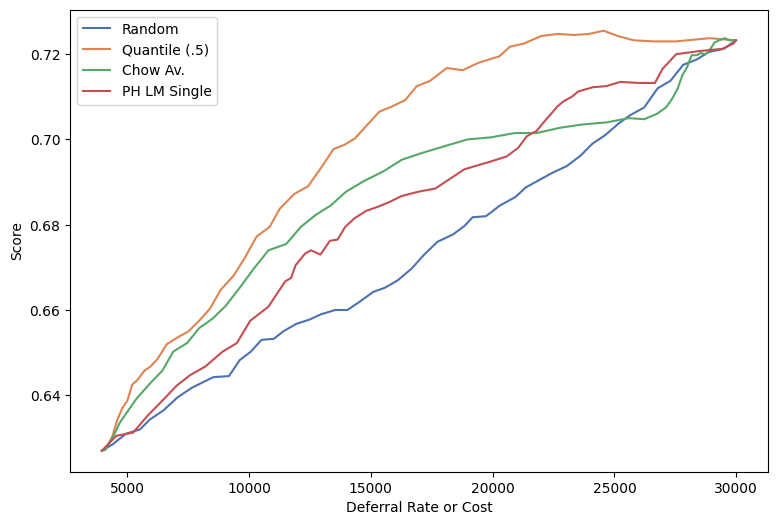

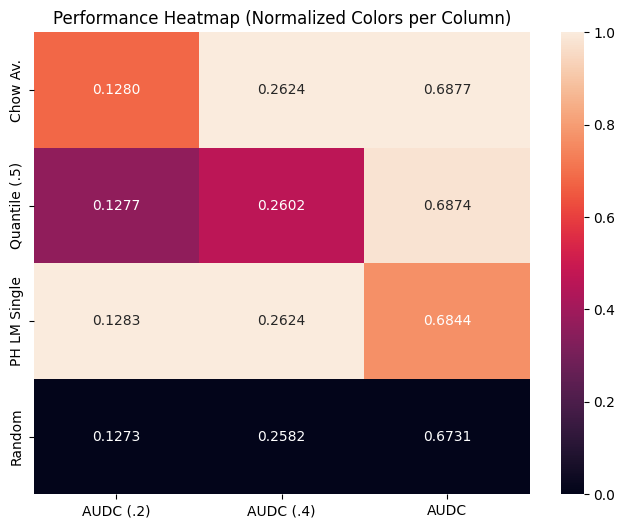

In [ ]:
  results = {}
  for d in DELEGATE_COLUMNS:
    results[d] = baseline_casc.evaluate_cascade_over_rates(d)
    #results[d] = casc.full_threshold_sim_temp(d, pref_def_column="pref_knowledge")
  all_results.append(results)
  display_results(results, DELEGATE_COLUMNS, primary_x="spend")
  true_baseline_results = results

# Single-Dim Knowledge 3-step

In [ ]:
for dataset in dataset_list:

 ######################################################### CASCADES PART

  casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["knowledge"], origin_cost = small_cost, metric_col=METRIC)


  ax_pos = (1,)
  casc.register_axis_data(df2, ax_pos, small_cost, stage=1)
  casc.register_axis_data(df5, (2,), large_cost, stage=2)

  casc.normalize_dfs()
  casc.compute_cv_splits()
  def_cols = DELEGATE_COLUMNS
  FIT_LM = True
  if FIT_LM:
    casc.fit_correctness_lm_at_tier(1,
          input_text_col="prompts_clean",
          output_text_col="res_clean",
          model_name="microsoft/deberta-v3-small",
          num_epochs=2,
          batch_size=16,
          learning_rate=2e-4,
          max_length=512,
          use_pos_weight=False,
          feature_cols=CHOW,
          normalize_features=True,
          threshold=0.5,
          score_col="post_hoc_conf",
          device=device,
          verbose=True
      )

  df1['preferred_deferral']  = [ax_pos]*len(df1)
  df2['preferred_deferral']  = [(2,)]*len(df2)
  #casc.fit_post_hoc_lm_at(casc.origin, "prompts", "responses", num_epochs=3, device=device)
  #casc.set_pref_deferral_at = types.MethodType(set_pref_deferral_at, casc)
  #casc.set_pref_deferral_at(casc.origin, "def_axis", offset=-1)




Registered ['knowledge: 1'] | Shape: (4000, 50) | Cost: (8, 48)
Registered ['knowledge: 2'] | Shape: (4000, 50) | Cost: (70, 420)
[fit_correctness_lm_at_tier] tier=[(1,)] | device=cuda
  pooled examples/fold-train ~= sum over positions of (fold!=f) rows
  n_features: 12 | normalize_features: True
  correctness rate [(1,)]: 0.6258


/content/colab_llm_utils/cascades.py:429: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['inf_cost'] = df['prompt_len'] * cost[0] + df['output_len'] * cost[1]
/content/colab_llm_utils/cascades.py:482: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  other_df['fold'] = origin_fold


  fold 1/4


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Finished epoch 1
Iteration 1 took 87.0159 seconds

================ Epoch 1/2 ================
Time Elapsed   : 97.08 seconds
Train Loss     : 0.6618
Validation Loss: 0.7431
Accuracy       : 0.6240
Precision (Mac): 0.7454
Recall (Macro) : 0.5317
F1-Score (Mac) : 0.4449
Finished epoch 2
Iteration 2 took 86.6365 seconds

================ Epoch 2/2 ================
Time Elapsed   : 96.69 seconds
Train Loss     : 0.5916
Validation Loss: 0.6202
Accuracy       : 0.6450
Precision (Mac): 0.7125
Recall (Macro) : 0.5629
F1-Score (Mac) : 0.5113
  fold 4/4


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Finished epoch 1
Iteration 1 took 86.6815 seconds

================ Epoch 1/2 ================
Time Elapsed   : 96.72 seconds
Train Loss     : 0.6806
Validation Loss: 0.6405
Accuracy       : 0.6400
Precision (Mac): 0.3200
Recall (Macro) : 0.5000
F1-Score (Mac) : 0.3902
Finished epoch 2
Iteration 2 took 86.3980 seconds

================ Epoch 2/2 ================
Time Elapsed   : 96.47 seconds
Train Loss     : 0.6507
Validation Loss: 0.6292
Accuracy       : 0.6550
Precision (Mac): 0.7385
Recall (Macro) : 0.5233
F1-Score (Mac) : 0.4429
---- correctness-LM sanity check ----
  score 'post_hoc_conf': min=0.231 max=0.993 mean=0.398 std=0.116
  detector AUROC (P(incorrect) vs is-incorrect): 0.6622  (want > 0.5)
  Kendall tau (score vs correct): -0.2220  (want negative)
  mean score | correct   samples: 0.3751
  mean score | incorrect samples: 0.4364
  (skipped deferral AUC probe: 'MultiaxialCascade' object has no attribute 'resolve_full_deferred_old')
--------------------------------------


                    auc     brier  kendall_tau      audc   audc_40
Chow Av.       0.677002  0.275900     0.242139  0.684387  0.259011
Quantile (.5)  0.656570  0.314331     0.214189  0.682277  0.256436
PH LM Single   0.719145  0.196777     0.299792  0.679032  0.260432


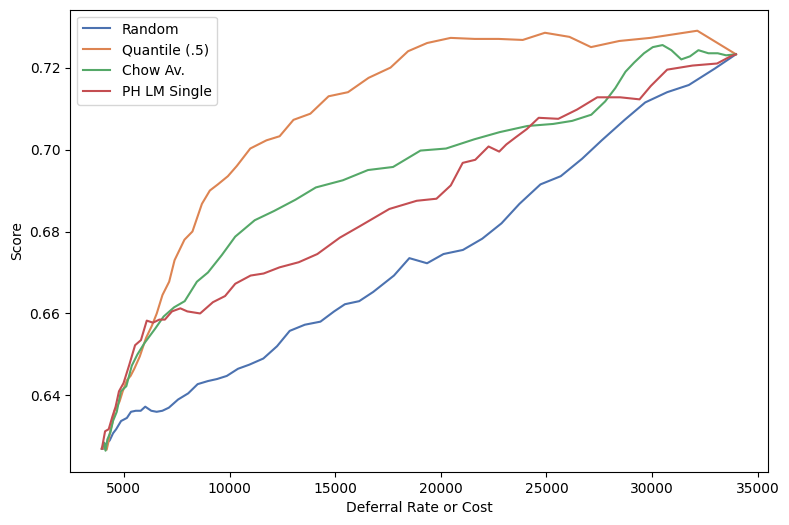

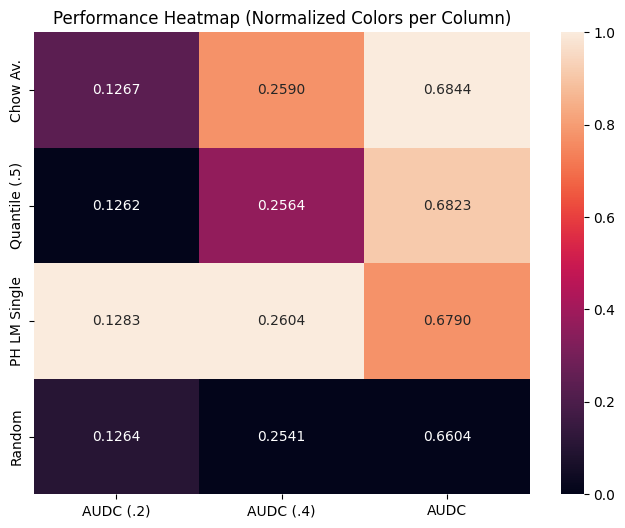

In [ ]:
  results = {}
  for d in def_cols:
    results[d] = casc.evaluate_cascade_over_rates(d)
    #results[d] = casc.full_threshold_sim_temp(d, pref_def_column="pref_knowledge")
  all_results.append(results)
  display_results(results, def_cols, primary_x = "spend")
  s_k_l_results = results

# Single-Dim Verify 3 Step

In [ ]:
for dataset in dataset_list:

 ######################################################### CASCADES PART

  casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["verify"], origin_cost = small_cost, metric_col=METRIC)


  ax_pos = (1,)
  casc.register_axis_data(df3, ax_pos, small_cost, stage=1)
  casc.register_axis_data(df5, (2,), large_cost, stage=2)

  casc.normalize_dfs()
  casc.compute_cv_splits()
  def_cols = DELEGATE_COLUMNS
  FIT_LM = True
  if FIT_LM:
    casc.fit_correctness_lm_at_tier(1,
          input_text_col="prompts_clean",
          output_text_col="res_clean",
          model_name="microsoft/deberta-v3-small",
          num_epochs=2,
          batch_size=16,
          learning_rate=2e-4,
          max_length=512,
          use_pos_weight=False,
          feature_cols=CHOW,
          normalize_features=True,
          threshold=0.5,
          score_col="post_hoc_conf",
          device=device,
          verbose=True
      )


  df1['preferred_deferral']  = [ax_pos]*len(df1)
  df3['preferred_deferral']  = [(2,)]*len(df3)




Registered ['verify: 1'] | Shape: (4000, 50) | Cost: (8, 48)
Registered ['verify: 2'] | Shape: (4000, 50) | Cost: (70, 420)
[fit_correctness_lm_at_tier] tier=[(1,)] | device=cuda
  pooled examples/fold-train ~= sum over positions of (fold!=f) rows
  n_features: 12 | normalize_features: True
  correctness rate [(1,)]: 0.6392


/content/colab_llm_utils/cascades.py:429: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['inf_cost'] = df['prompt_len'] * cost[0] + df['output_len'] * cost[1]
/content/colab_llm_utils/cascades.py:429: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['inf_cost'] = df['prompt_len'] * cost[0] + df['output_len'] * cost[1]
/content/colab_llm_utils/cascades.py:482: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead


  fold 1/4


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

Finished epoch 1
Iteration 1 took 86.5802 seconds

================ Epoch 1/2 ================
Time Elapsed   : 96.62 seconds
Train Loss     : 0.6476
Validation Loss: 0.6290
Accuracy       : 0.6700
Precision (Mac): 0.6987
Recall (Macro) : 0.5723
F1-Score (Mac) : 0.5397
Finished epoch 2
Iteration 2 took 86.3160 seconds

================ Epoch 2/2 ================
Time Elapsed   : 96.38 seconds
Train Loss     : 0.5657
Validation Loss: 0.5698
Accuracy       : 0.7260
Precision (Mac): 0.7183
Recall (Macro) : 0.6730
F1-Score (Mac) : 0.6798
  fold 4/4


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Finished epoch 1
Iteration 1 took 86.7135 seconds

================ Epoch 1/2 ================
Time Elapsed   : 96.75 seconds
Train Loss     : 0.6555
Validation Loss: 0.6243
Accuracy       : 0.6370
Precision (Mac): 0.5686
Recall (Macro) : 0.5006
F1-Score (Mac) : 0.3917
Finished epoch 2
Iteration 2 took 86.5199 seconds

================ Epoch 2/2 ================
Time Elapsed   : 96.55 seconds
Train Loss     : 0.6192
Validation Loss: 0.5550
Accuracy       : 0.7410
Precision (Mac): 0.7513
Recall (Macro) : 0.6699
F1-Score (Mac) : 0.6778
---- correctness-LM sanity check ----
  score 'post_hoc_conf': min=0.145 max=0.910 mean=0.392 std=0.153
  detector AUROC (P(incorrect) vs is-incorrect): 0.6857  (want > 0.5)
  Kendall tau (score vs correct): -0.2522  (want negative)
  mean score | correct   samples: 0.3536
  mean score | incorrect samples: 0.4611
  (skipped deferral AUC probe: 'MultiaxialCascade' object has no attribute 'resolve_full_deferred_old')
--------------------------------------


/content/colab_llm_utils/cascades.py:1291: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['preferred_deferral_lm'] = [tuple(l)] * len(df)
/tmp/ipykernel_3258/2458373201.py:36: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3['preferred_deferral']  = [(2,)]*len(df3)


                    auc     brier  kendall_tau      audc   audc_40
Quantile (.5)  0.656570  0.314331     0.214189  0.678701  0.255939
Chow Av.       0.677002  0.275900     0.242139  0.677865  0.256939
PH LM Single   0.719145  0.196777     0.299792  0.672265  0.258315


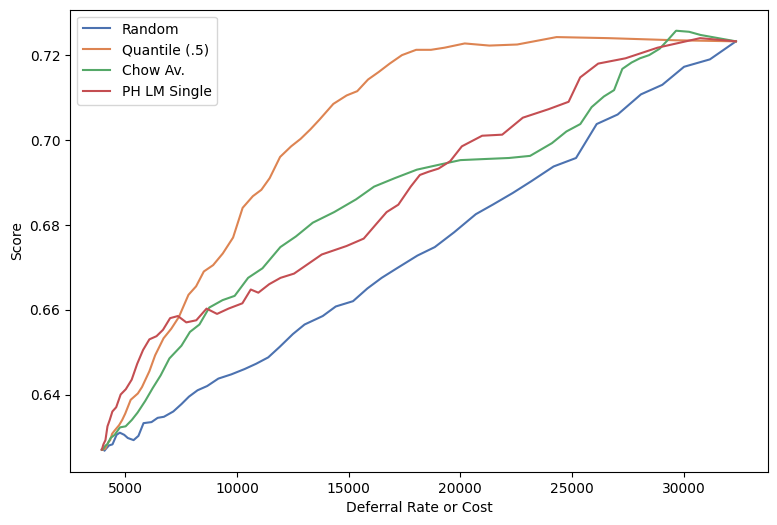

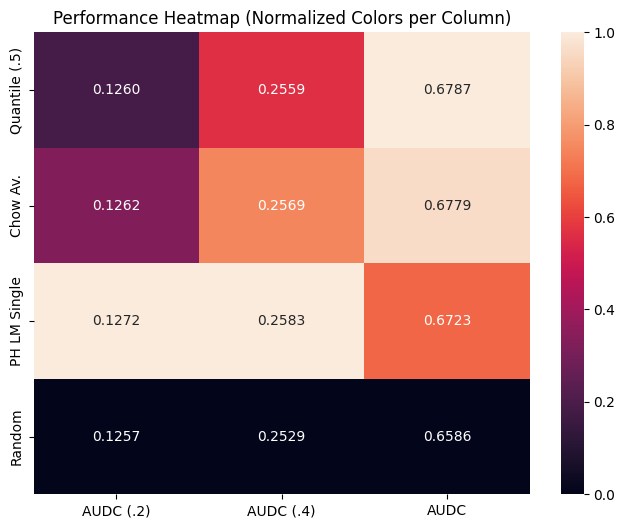

In [ ]:
  results = {}
  for d in def_cols:
    results[d] = casc.evaluate_cascade_over_rates(d)
    #results[d] = casc.full_threshold_sim_temp(d, pref_def_column="pref_knowledge")
  all_results.append(results)
  display_results(results, def_cols, primary_x = "spend")
  s_v_l_results = results

# Single-Dim Structure 3 Step

In [ ]:
for dataset in dataset_list:

 ######################################################### CASCADES PART

  casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["structure"], origin_cost = small_cost, metric_col=METRIC)


  ax_pos = (1,)
  casc.register_axis_data(df4, ax_pos, small_cost, stage=1)
  casc.register_axis_data(df5, (2,), large_cost, stage=2)

  casc.normalize_dfs()
  casc.compute_cv_splits()
  def_cols = DELEGATE_COLUMNS
  FIT_LM = True
  if FIT_LM:
    casc.fit_correctness_lm_at_tier(1,
          input_text_col="prompts_clean",
          output_text_col="res_clean",
          model_name="microsoft/deberta-v3-small",
          num_epochs=2,
          batch_size=16,
          learning_rate=2e-4,
          max_length=512,
          use_pos_weight=False,
          feature_cols=CHOW,
          normalize_features=True,
          threshold=0.5,
          score_col="post_hoc_conf",
          device=device,
          verbose=True
      )
  df1['preferred_deferral']  = [ax_pos]*len(df1)
  df4['preferred_deferral']  = [(2,)]*len(df4)







Registered ['structure: 1'] | Shape: (4000, 49) | Cost: (8, 48)
Registered ['structure: 2'] | Shape: (4000, 50) | Cost: (70, 420)
[fit_correctness_lm_at_tier] tier=[(1,)] | device=cuda
  pooled examples/fold-train ~= sum over positions of (fold!=f) rows
  n_features: 12 | normalize_features: True
  correctness rate [(1,)]: 0.6627


/content/colab_llm_utils/cascades.py:429: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['inf_cost'] = df['prompt_len'] * cost[0] + df['output_len'] * cost[1]
/content/colab_llm_utils/cascades.py:482: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  other_df['fold'] = origin_fold


  fold 1/4


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Finished epoch 1
Iteration 1 took 86.5354 seconds

================ Epoch 1/2 ================
Time Elapsed   : 96.56 seconds
Train Loss     : 0.5994
Validation Loss: 0.5686
Accuracy       : 0.7410
Precision (Mac): 0.7641
Recall (Macro) : 0.6354
F1-Score (Mac) : 0.6393
Finished epoch 2
Iteration 2 took 86.2211 seconds

================ Epoch 2/2 ================
Time Elapsed   : 96.26 seconds
Train Loss     : 0.5118
Validation Loss: 0.5598
Accuracy       : 0.7780
Precision (Mac): 0.7708
Recall (Macro) : 0.7100
F1-Score (Mac) : 0.7247
  fold 4/4


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Finished epoch 1
Iteration 1 took 86.5163 seconds

================ Epoch 1/2 ================
Time Elapsed   : 96.56 seconds
Train Loss     : 0.6036
Validation Loss: 0.5979
Accuracy       : 0.7790
Precision (Mac): 0.7569
Recall (Macro) : 0.7431
F1-Score (Mac) : 0.7487
Finished epoch 2
Iteration 2 took 86.3594 seconds

================ Epoch 2/2 ================
Time Elapsed   : 96.41 seconds
Train Loss     : 0.5114
Validation Loss: 0.4683
Accuracy       : 0.8020
Precision (Mac): 0.8094
Recall (Macro) : 0.7399
F1-Score (Mac) : 0.7571
---- correctness-LM sanity check ----
  score 'post_hoc_conf': min=0.086 max=0.971 mean=0.383 std=0.239
  detector AUROC (P(incorrect) vs is-incorrect): 0.7835  (want > 0.5)
  Kendall tau (score vs correct): -0.3792  (want negative)
  mean score | correct   samples: 0.2952
  mean score | incorrect samples: 0.5551
  (skipped deferral AUC probe: 'MultiaxialCascade' object has no attribute 'resolve_full_deferred_old')
--------------------------------------


                    auc     brier  kendall_tau      audc   audc_40
Chow Av.       0.677002  0.275900     0.242139  0.684542  0.260929
Quantile (.5)  0.656570  0.314331     0.214189  0.684462  0.258441
PH LM Single   0.719145  0.196777     0.299792  0.680936  0.258779


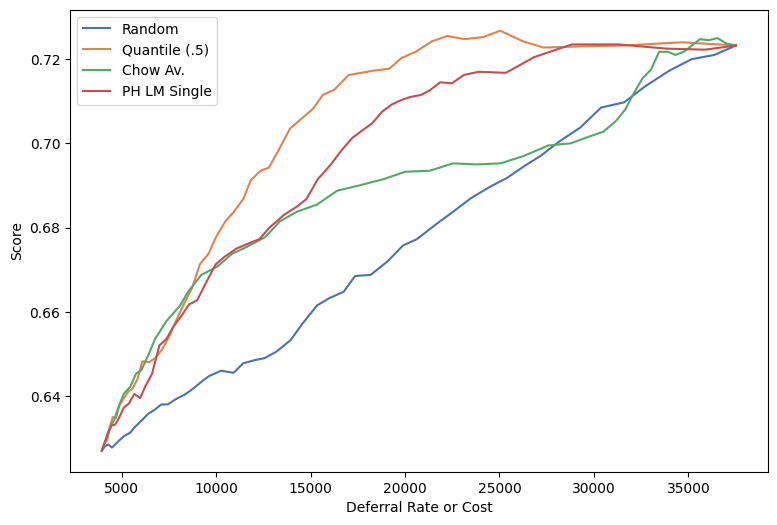

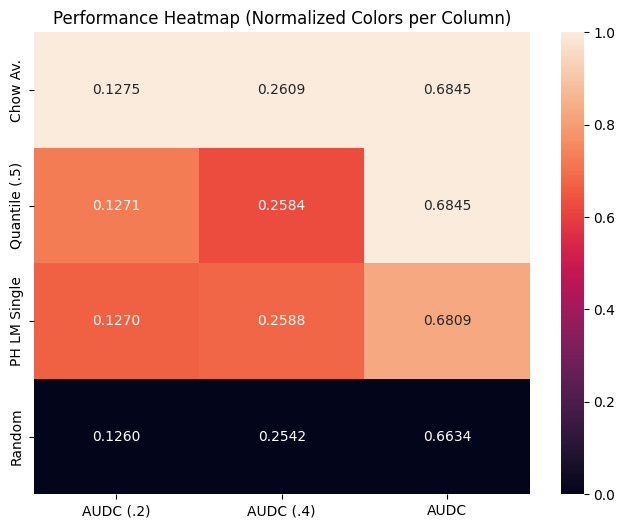

In [ ]:
  results = {}
  for d in def_cols:
    results[d] = casc.evaluate_cascade_over_rates(d)
    #results[d] = casc.full_threshold_sim_temp(d, pref_def_column="pref_knowledge")
  all_results.append(results)
  display_results(results, def_cols, primary_x='spend')
  s_st_l_results = results

In [ ]:
r_subset = {}
def_col = "normed_log_chow_av"
r_subset['Baseline S-L'] = true_baseline_results[def_col]
r_subset['S-K-L'] = s_k_l_results[def_col]
r_subset['S-St-L'] = s_st_l_results[def_col]
r_subset['S-V-L'] = s_v_l_results[def_col]
#r_subset['S-(St-K)-L'] = s_st_k_l_results['chow_av']
try:
  display_results(r_subset, r_subset.keys(), primary_x = "spend")
except:
  pass

## Linear 5 Step

In [ ]:
for dataset in dataset_list:

 ######################################################### CASCADES PART

  casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["combined"], origin_cost = small_cost, metric_col=METRIC, k=4)
  casc.register_axis_data(df4, (1,), small_cost, stage=1)
  casc.register_axis_data(df3, (2,), small_cost, stage=2)
  casc.register_axis_data(df2, (3,), small_cost, stage=3)
  casc.register_axis_data(df5, (4,), large_cost, stage=4)


  casc.normalize_dfs()
  casc.compute_cv_splits()

  df1['preferred_deferral'] =  [(1,)]*len(df1)
  df4['preferred_deferral']  = [(2,)]*len(df4)
  df2['preferred_deferral']  = [(3,)]*len(df2)
  df3['preferred_deferral']  = [(4,)]*len(df3)
  #casc.pref_def_registry[casc.origin] = "preferred_deferral_lm"



Registered ['combined: 1'] | Shape: (4000, 53) | Cost: (8, 48)
Registered ['combined: 2'] | Shape: (4000, 54) | Cost: (8, 48)
Registered ['combined: 3'] | Shape: (4000, 53) | Cost: (8, 48)
Registered ['combined: 4'] | Shape: (4000, 50) | Cost: (70, 420)


/content/colab_llm_utils/cascades.py:429: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['inf_cost'] = df['prompt_len'] * cost[0] + df['output_len'] * cost[1]
/content/colab_llm_utils/cascades.py:429: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['inf_cost'] = df['prompt_len'] * cost[0] + df['output_len'] * cost[1]
/content/colab_llm_utils/cascades.py:482: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead


                    auc     brier  kendall_tau      audc   audc_40
Chow Av.       0.677002  0.275900     0.242139  0.680421  0.259426
Quantile (.5)  0.656570  0.314331     0.214189  0.679606  0.257359
PH LM Single   0.719145  0.196777     0.299792  0.674481  0.258294


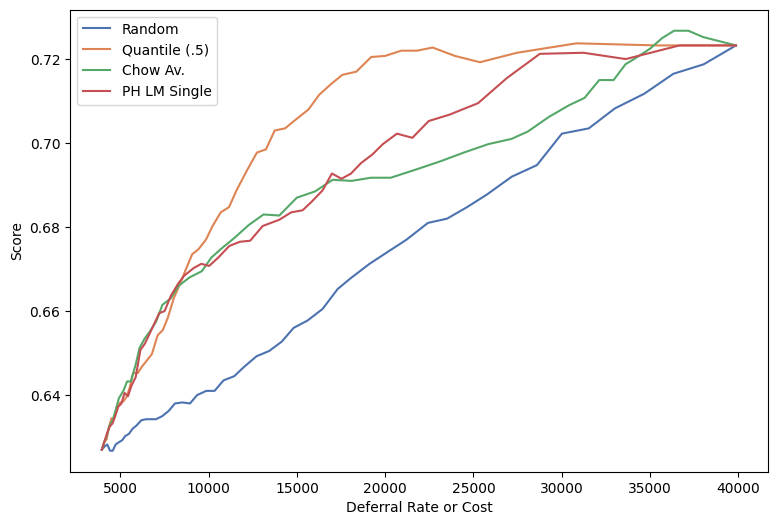

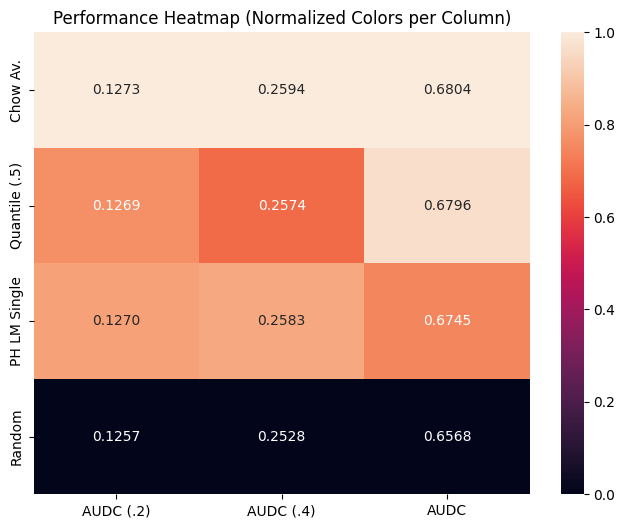

In [ ]:
results = {}
for d in DELEGATE_COLUMNS:
    results[d] = casc.evaluate_cascade_over_rates(d)
    #results[d] = casc.full_threshold_sim_temp(d, pref_def_column='preferred_deferral_lm')
all_results.append(results)
display_results(results, DELEGATE_COLUMNS, primary_x = "spend")
s_st_v_k_l_lin_results = results

## Three Way Multilabel

In [ ]:
device = "cuda"

In [ ]:
df_retain = df1.copy()


In [ ]:


for dataset in dataset_list:

 ######################################################### CASCADES PART

  casc_retain = colab_llm_utils.cascades.MultiaxialCascade(df1, ["structure", "verify", "knowledge", "retain"], origin_cost = small_cost, metric_col=METRIC, k=4)
  casc_retain.register_axis_data(df4, (1,0,0,0), small_cost, stage=1)
  casc_retain.register_axis_data(df3, (0,1,0,0), small_cost, stage=1)
  casc_retain.register_axis_data(df2, (0,0,1,0), small_cost, stage=1)
  casc_retain.register_axis_data(df_retain, (0,0,0,1), (0,0), stage=1)
  casc_retain.register_axis_data(df5, (2,2,2,2), large_cost, stage=2)


  casc_retain.normalize_dfs()
  casc_retain.compute_cv_splits()

  #casc.fit_post_hoc_at = types.MethodType(fit_post_hoc_at, casc)
  FIT_LM = True
  if FIT_LM:
      casc_retain.fit_correctness_lm_at_tier(1, "prompts", "res_clean",
        num_epochs=1,
        learning_rate=2e-5,
        feature_cols=CHOW,
        normalize_features=True,
        use_pos_weight=False,                  # <-- re-enable, targets are sparse
        device=device,
        model_name="microsoft/deberta-v3-small",
        verbose=True)
  FIT_AX_MODEL = True
  if FIT_AX_MODEL:
      casc_retain.fit_post_hoc_lm_at(casc_retain.origin, "prompts_clean", "res_clean",
        num_epochs=3,
        multilabel=True,
        learning_rate=2e-5,
        feature_cols=None,
        recovery_fn = lambda base, axis: (axis > 0).astype(np.float32),
        normalize_features=True,
        use_pos_weight=False,                  # <-- re-enable, targets are sparse
        device=device,
        model_name="microsoft/deberta-v3-base",
        verbose=True)

    #casc.set_pref_deferral_at = types.MethodType(set_pref_deferral_at, casc)
    #casc.set_pref_deferral_at(casc.origin, "def_axis", offset=-1)
    #casc.set_cost_adjusted_pref(casc.origin, lam=1.5, cost_norm="max")
  df4['preferred_deferral']  = [(2,2,2,2,)]*len(df4)
  df3['preferred_deferral']  = [(2,2,2,2,)]*len(df3)
  df2['preferred_deferral']  = [(2,2,2,2,)]*len(df2)
  df_retain['preferred_deferral'] = [(2,2,2,2,)]*len(df_retain)

  casc_retain.pref_def_registry[casc_retain.origin] = "preferred_deferral_lm"



Registered ['structure: 1', 'verify: 0', 'knowledge: 0', 'retain: 0'] | Shape: (4000, 53) | Cost: (8, 48)
Registered ['structure: 0', 'verify: 1', 'knowledge: 0', 'retain: 0'] | Shape: (4000, 54) | Cost: (8, 48)
Registered ['structure: 0', 'verify: 0', 'knowledge: 1', 'retain: 0'] | Shape: (4000, 53) | Cost: (8, 48)
Registered ['structure: 0', 'verify: 0', 'knowledge: 0', 'retain: 1'] | Shape: (4000, 53) | Cost: (0, 0)
Registered ['structure: 2', 'verify: 2', 'knowledge: 2', 'retain: 2'] | Shape: (4000, 50) | Cost: (70, 420)
[fit_correctness_lm_at_tier] tier=[(1, 0, 0, 0), (0, 1, 0, 0), (0, 0, 1, 0), (0, 0, 0, 1)] | device=cuda
  pooled examples/fold-train ~= sum over positions of (fold!=f) rows
  n_features: 12 | normalize_features: True
  correctness rate [(1, 0, 0, 0)]: 0.6627
  correctness rate [(0, 1, 0, 0)]: 0.6392
  correctness rate [(0, 0, 1, 0)]: 0.6258
  correctness rate [(0, 0, 0, 1)]: 0.6270


/content/colab_llm_utils/cascades.py:429: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['inf_cost'] = df['prompt_len'] * cost[0] + df['output_len'] * cost[1]
/content/colab_llm_utils/cascades.py:429: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['inf_cost'] = df['prompt_len'] * cost[0] + df['output_len'] * cost[1]
/content/colab_llm_utils/cascades.py:482: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead


  fold 1/4


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

Finished epoch 1
Iteration 1 took 97.1812 seconds

================ Epoch 1/3 (multilabel) ================
Time Elapsed     : 116.69 seconds
Train Loss       : 0.6015
Validation Loss  : 0.7215
Exact-match Acc  : 0.1960
Macro P/R/F1     : 0.7902 / 0.4378 / 0.5004
Micro P/R/F1     : 0.8163 / 0.4776 / 0.6026
Finished epoch 2
Iteration 2 took 97.4430 seconds

================ Epoch 2/3 (multilabel) ================
Time Elapsed     : 116.94 seconds
Train Loss       : 0.5455
Validation Loss  : 0.7345
Exact-match Acc  : 0.1830
Macro P/R/F1     : 0.7949 / 0.4244 / 0.4981
Micro P/R/F1     : 0.8181 / 0.4631 / 0.5914
Finished epoch 3
Iteration 3 took 97.3482 seconds

================ Epoch 3/3 (multilabel) ================
Time Elapsed     : 116.80 seconds
Train Loss       : 0.5049
Validation Loss  : 0.7186
Exact-match Acc  : 0.1860
Macro P/R/F1     : 0.8000 / 0.4623 / 0.5479
Micro P/R/F1     : 0.8253 / 0.4954 / 0.6191
Training fold 4/4


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Finished epoch 1
Iteration 1 took 99.3060 seconds

================ Epoch 1/3 (multilabel) ================
Time Elapsed     : 118.75 seconds
Train Loss       : 0.6018
Validation Loss  : 0.7384
Exact-match Acc  : 0.2070
Macro P/R/F1     : 0.6326 / 0.3985 / 0.4399
Micro P/R/F1     : 0.8430 / 0.4380 / 0.5765
Finished epoch 2
Iteration 2 took 99.1643 seconds

================ Epoch 2/3 (multilabel) ================
Time Elapsed     : 118.65 seconds
Train Loss       : 0.5580
Validation Loss  : 0.6969
Exact-match Acc  : 0.2070
Macro P/R/F1     : 0.8300 / 0.4401 / 0.5110
Micro P/R/F1     : 0.8485 / 0.4753 / 0.6093
Finished epoch 3
Iteration 3 took 99.2425 seconds

================ Epoch 3/3 (multilabel) ================
Time Elapsed     : 118.68 seconds
Train Loss       : 0.5175
Validation Loss  : 0.7253
Exact-match Acc  : 0.2170
Macro P/R/F1     : 0.8408 / 0.4276 / 0.5126
Micro P/R/F1     : 0.8563 / 0.4601 / 0.5986
Completed fit_post_hoc_lm_at at position (0, 0, 0, 0) (multilabel=True, n_fe

/tmp/ipykernel_3258/6709293.py:46: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3['preferred_deferral']  = [(2,2,2,2,)]*len(df3)


                    auc     brier  kendall_tau      audc   audc_40
Chow Av.       0.677002  0.275900     0.242139  0.685989  0.259443
PH LM Single   0.719145  0.196777     0.299792  0.684432  0.262122
Quantile (.5)  0.656570  0.314331     0.214189  0.683532  0.256226


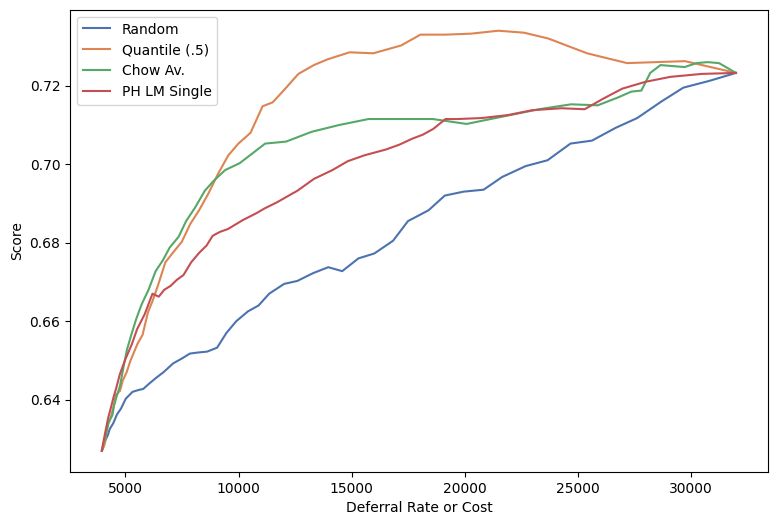

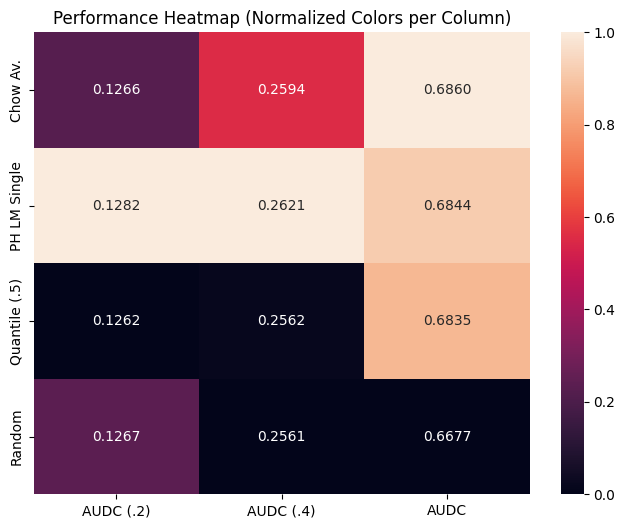

In [ ]:
  results = {}
  for d in DELEGATE_COLUMNS:
    results[d] = casc_retain.evaluate_cascade_over_rates(d)
    #results[d] = casc.full_threshold_sim_temp(d, pref_def_column='preferred_deferral_lm')
  all_results.append(results)
  display_results(results, DELEGATE_COLUMNS, primary_x="spend")
  s_stvkr_l_results = results

In [ ]:
for dataset in dataset_list:

 ######################################################### CASCADES PART

  casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["structure", "verify", "knowledge"], origin_cost = small_cost, metric_col=METRIC, k=4)
  casc.register_axis_data(df4, (1,0,0,), small_cost, stage=2)
  casc.register_axis_data(df3, (0,1,0,), small_cost, stage=2)
  casc.register_axis_data(df2, (0,0,1,), small_cost, stage=2)
  #casc.register_axis_data(df_retain, (0,0,0,1), (0,0), stage=2)
  casc.register_axis_data(df5, (2,2,2,), large_cost, stage=3)


  casc.normalize_dfs()
  casc.compute_cv_splits()

  #casc.fit_post_hoc_at = types.MethodType(fit_post_hoc_at, casc)
  FIT_LM = False
  if FIT_LM:
      casc.fit_correctness_lm_at_tier(1, "prompts", "res_clean",
        num_epochs=1,
        learning_rate=2e-5,
        feature_cols=CHOW,
        normalize_features=True,
        use_pos_weight=False,                  # <-- re-enable, targets are sparse
        device=device,
        model_name="microsoft/deberta-v3-small",
        verbose=True)
  FIT_AX_MODEL = True
  if FIT_AX_MODEL:
      casc.fit_post_hoc_lm_at(casc.origin, "prompts_clean", "res_clean",
        num_epochs=2,
        multilabel=True,
        learning_rate=2e-5,
        feature_cols=CHOW,
        recovery_fn = lambda base, axis: (axis > 0).astype(np.float32),
        normalize_features=True,
        use_pos_weight=False,                  # <-- re-enable, targets are sparse
        device=device,
        model_name="microsoft/deberta-v3-small",
        verbose=True)

    #casc.set_pref_deferral_at = types.MethodType(set_pref_deferral_at, casc)
    #casc.set_pref_deferral_at(casc.origin, "def_axis", offset=-1)
    #casc.set_cost_adjusted_pref(casc.origin, lam=1.5, cost_norm="max")
  df4['preferred_deferral']  = [(2,2,2,)]*len(df4)
  df3['preferred_deferral']  = [(2,2,2,)]*len(df3)
  df2['preferred_deferral']  = [(2,2,2,)]*len(df2)
  df_retain['preferred_deferral'] = [(2,2,2,)]*len(df_retain)

  casc.pref_def_registry[casc.origin] = "preferred_deferral_lm"



Registered ['structure: 1', 'verify: 0', 'knowledge: 0'] | Shape: (4000, 53) | Cost: (8, 48)
Registered ['structure: 0', 'verify: 1', 'knowledge: 0'] | Shape: (4000, 54) | Cost: (8, 48)
Registered ['structure: 0', 'verify: 0', 'knowledge: 1'] | Shape: (4000, 53) | Cost: (8, 48)
Registered ['structure: 2', 'verify: 2', 'knowledge: 2'] | Shape: (4000, 50) | Cost: (70, 420)
mode: multilabel
n_outputs: 3 | n_features: 12 | normalize_features: True | device: cuda
  recovery rate [structure]: 0.6628
  recovery rate [verify]: 0.6392
  recovery rate [knowledge]: 0.6258


/content/colab_llm_utils/cascades.py:429: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['inf_cost'] = df['prompt_len'] * cost[0] + df['output_len'] * cost[1]
/content/colab_llm_utils/cascades.py:429: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['inf_cost'] = df['prompt_len'] * cost[0] + df['output_len'] * cost[1]
/content/colab_llm_utils/cascades.py:482: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead


Training fold 1/4


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

Finished epoch 1
Iteration 1 took 30.7879 seconds

================ Epoch 1/2 (multilabel) ================
Time Elapsed     : 40.96 seconds
Train Loss       : 0.6522
Validation Loss  : 0.6648
Exact-match Acc  : 0.1170
Macro P/R/F1     : 0.6894 / 0.6637 / 0.6672
Micro P/R/F1     : 0.6979 / 0.6713 / 0.6843
Finished epoch 2
Iteration 2 took 30.8481 seconds

================ Epoch 2/2 (multilabel) ================
Time Elapsed     : 41.08 seconds
Train Loss       : 0.6118
Validation Loss  : 0.6819
Exact-match Acc  : 0.1170
Macro P/R/F1     : 0.7087 / 0.6197 / 0.6528
Micro P/R/F1     : 0.7087 / 0.6247 / 0.6640
Training fold 4/4


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Finished epoch 1
Iteration 1 took 31.9715 seconds

================ Epoch 1/2 (multilabel) ================
Time Elapsed     : 42.18 seconds
Train Loss       : 0.6473
Validation Loss  : 0.6842
Exact-match Acc  : 0.1130
Macro P/R/F1     : 0.7267 / 0.6082 / 0.6265
Micro P/R/F1     : 0.7164 / 0.6115 / 0.6598
Finished epoch 2
Iteration 2 took 31.9475 seconds

================ Epoch 2/2 (multilabel) ================
Time Elapsed     : 42.12 seconds
Train Loss       : 0.6128
Validation Loss  : 0.6833
Exact-match Acc  : 0.1160
Macro P/R/F1     : 0.7117 / 0.6126 / 0.6391
Micro P/R/F1     : 0.7225 / 0.6156 / 0.6648
Completed fit_post_hoc_lm_at at position (0, 0, 0) (multilabel=True, n_features=12)


/tmp/ipykernel_3258/758758811.py:46: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3['preferred_deferral']  = [(2,2,2,)]*len(df3)


In [ ]:
  results = {}
  for d in DELEGATE_COLUMNS:
    results[d] = casc.evaluate_cascade_over_rates(d)
    #results[d] = casc.full_threshold_sim_temp(d, pref_def_column='preferred_deferral_lm')
  all_results.append(results)
  display_results(results, DELEGATE_COLUMNS, primary_x="spend")
  s_stvk_l_results = results

In [ ]:
#for df in dataframes:
#  df['prompt_len'] = [len(p.split()) for p in df.prompts]

In [ ]:
true_baseline_results.keys()

dict_keys(['random', 'normed_chow_quantile', 'normed_log_chow_av', 'post_hoc_conf'])

In [ ]:
r_subset = {}
def_col = 'normed_log_chow_av'
r_subset['Baseline S-L'] = true_baseline_results[def_col]
#r_subset['S-K-L'] = s_k_l_results[def_col]
#r_subset['S-St-L'] = s_st_l_results[def_col]
#r_subset['S-V-L'] = s_v_l_results[def_col]
r_subset['S-(St-v-K)-L'] = s_stvk_l_results[def_col]
r_subset['S-(St-v-K-r)-L'] = s_stvkr_l_results[def_col]
r_subset['S-St-v-K-L'] = s_st_v_k_l_lin_results[def_col]
try:
  display_results(r_subset, r_subset.keys(), primary_x = "spend")
except:
  pass

In [ ]:
df_retain['post_hoc_conf'] = df1['post_hoc_conf']

In [ ]:
for df in dataframes:
  print(df['inf_cost'].sum())

In [ ]:
df_retain['post_hoc_conf']  = df1['post_hoc_conf'] + 1
df1['preferred_deferral_lm'] = [(0,0,0,1,)]* len(df1)
#df1_prefcop = df1['preferred_deferral_lm'].copy()
#df1['preferred_deferral_lm'] = df1_prefcop

In [ ]:
df2[df1_prefcop == (0, 0, 1, 0,)]["inf_cost"].mean()

In [ ]:
df2[~(df1_prefcop == (0, 0, 1, 0,))]["inf_cost"].mean()

In [ ]:
df2[df1_prefcop == (0, 0, 1, 0,)][['prompts', 'prompt_len', 'output_len', 'inf_cost']]

In [ ]:
df5[df1_prefcop == (0, 0, 1, 0,)][['prompt_len', 'output_len', 'inf_cost']]

In [ ]:
df1['preferred_deferral_lm'].value_counts()

In [ ]:
df1[['prompts', 'responses', 'inf_cost']].head()

In [ ]:
, df4[['prompts', 'responses', 'inf_cost']].head()

In [ ]:
df5[['prompts', 'responses', 'inf_cost']].head()

In [ ]:
print(f"inf cost 1: {df1['inf_cost'].mean()}")
print(f"inf cost 2: {df2['inf_cost'].mean()}")
print(f"inf cost 3: {df3['inf_cost'].mean()}")
print(f"inf cost 4: {df4['inf_cost'].mean()}")
print(f"inf_cost 5: {df5['inf_cost'].mean()}")
#

In [ ]:
for d in dataframes:
  print("****************************************************************************************************")
  print(d['prompts'][0])
  print(d['responses'][0])
  print(d['ans'][0])
  print(d[METRIC][0])
  print(f"acc start: {d[:2000][METRIC].mean()} ")
  print(f"acc end: {d[2000:][METRIC].mean()}")

In [ ]:
df1[2000:2010]

In [ ]:
# Overlay learned + oracle router points on a cascade frontier `s_st_l_results`
import matplotlib.pyplot as plt

plt.figure()
for d, res in s_st_l_results.items():                # cascade curves
    plt.plot(res['spend'], res['accs'], label=f"cascade:{d}", alpha=0.6)

for name, res in router_results.items():             # single router points
    plt.scatter(res['route_spend'], res['route_acc'], marker='*', s=160, label=name, zorder=5)

plt.xlabel('spend'); plt.ylabel('accuracy'); plt.legend(); plt.show()

In [ ]:
from google.colab import runtime
runtime.unassign()

## Two-Way Oracle Axis


In [ ]:
for dataset in dataset_list:

 ######################################################### CASCADES PART

  casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["knowledge", "reasoning"], metric_col="correct")
  casc.register_axis_data(df2, (1,0,), (1,6))
  casc.register_axis_data(df4, (0,1,), (1,6))


  casc.normalize_dfs()
  casc.compute_cv_splits()
  casc.set_oracle_pref_deferral_at(casc.origin, tie_breaker=colab_llm_utils.misc.basic_idxmax, allow_keep=False)
  #casc.fit_post_hoc_at = types.MethodType(fit_post_hoc_at, casc)


  results = {}
  for d in DELEGATE_COLUMNS:
    results[d] = casc.full_threshold_sim_temp(d, pref_def_column='oracle_preferred_deferral')
  all_results.append(results)
  display_results(results, DELEGATE_COLUMNS)

## Three-Way Oracle

In [ ]:
THREE_WAY = False
if THREE_WAY:
  for dataset in dataset_list:

  ######################################################### CASCADES PART

    casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["knowledge", "reasoning", "structure"], metric_col="correct")
    casc.register_axis_data(df2, (1,0,0,), (1,6))
    casc.register_axis_data(df3, (0,1,0,), (1,6))
    casc.register_axis_data(df4, (0,0,1,), (1,6))

    casc.normalize_dfs()
    casc.compute_cv_splits()
    casc.set_oracle_pref_deferral_at(casc.origin, tie_breaker=colab_llm_utils.misc.basic_idxmax, allow_keep=False)
    #casc.fit_post_hoc_at = types.MethodType(fit_post_hoc_at, casc)


    results = {}
    for d in DELEGATE_COLUMNS:
      results[d] = casc.full_threshold_sim_temp(d, pref_def_column='oracle_preferred_deferral')
    all_results.append(results)
    display_results(results)

In [ ]:
def_ax = [(1,0,)]*2000
def_ax.extend(([(0,1,)]*2000))
df1['preferred_deferral_naive'] =  def_ax
df1['preferred_deferral_naive'].value_counts()

## Two Way Naive

In [ ]:
for dataset in dataset_list:

 ######################################################### CASCADES PART

  casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["structure", "knowledge"], metric_col="correct", k=4)
  casc.register_axis_data(df4, (1,0,), 1.5)
  casc.register_axis_data(df2, (0,1,), 1.1)

  casc.normalize_dfs()
  casc.compute_cv_splits()
  #casc.fit_post_hoc_at = types.MethodType(fit_post_hoc_at, casc)
  FIT_AX_MODEL = False
  if FIT_AX_MODEL:
    ret = casc.fit_post_hoc_lm_at(casc.origin, "prompts", "res_clean",
                            num_epochs=2,
                            multilabel=True,
                            learning_rate=1e-3,
                            target_func=colab_llm_utils.misc.basic_idxmax,
                            simple_def_col="post_hoc_conf",
                            #recovery_fn = lambda base, axis: (axis > 0).astype(np.float32),
                            feature_cols=CHOW,
                            normalize_features=True,

                            device=device,
                            model_name="microsoft/deberta-v3-small",
                            use_pos_weight = False,
                            verbose=True)
  #casc.set_pref_deferral_at = types.MethodType(set_pref_deferral_at, casc)
  #casc.set_pref_deferral_at(casc.origin, "def_axis", offset=-1)
    casc.set_cost_adjusted_pref(casc.origin, lam=1.5, cost_norm="max")

  results = {}
  for d in DELEGATE_COLUMNS:
    results[d] = casc.full_threshold_sim_temp(d, pref_def_column='preferred_deferral_naive')
  all_results.append(results)
  display_results(results, DELEGATE_COLUMNS)

In [ ]:
pref_def_cols = ['prefer_knowledge', 'prefer_structure', 'preferred_deferral_lm', 'preferred_deferral_naive']
for dc in pref_def_cols:
  CLEAN_NAME_DICT[dc] = dc

In [ ]:
df1['prefer_structure'] = [(1,0,)] *4000
df1['prefer_knowledge'] = [(0,1,)] *4000

In [ ]:
casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["structure", "knowledge"], metric_col="correct", k=4)
casc.register_axis_data(df4, (1,0,), 1.5)
casc.register_axis_data(df2, (0,1,), 1.1)
FIT_AX_MODEL = True
if FIT_AX_MODEL:
    ret = casc.fit_post_hoc_lm_at(casc.origin, "prompts", "res_clean",
    num_epochs=8,
    multilabel=True,
    learning_rate=3e-5,
    feature_cols=CHOW,
    recovery_fn = lambda base, axis: (axis > 0).astype(np.float32)
    normalize_features=True,
    use_pos_weight=True,                  # <-- re-enable, targets are sparse
    device=device,
    model_name="microsoft/deberta-v3-small",
    verbose=True)

In [ ]:
print((df1['preferred_deferral_lm'] == df1['prefer_knowledge']).value_counts())
print(casc.resolve_full_deferred(casc.origin, pref_def_column='preferred_deferral_lm')['correct'].mean())
print(casc.resolve_full_deferred(casc.origin, pref_def_column='prefer_knowledge')['correct'].mean())

In [ ]:
df1[METRIC].mean()

## Routing Baseline

In [ ]:
# ---- ROUTING BASELINE ----------------------------------------------------
# Single tier: the router picks ONE candidate model per sample using inputs
# only, and pays only that model's inference cost. df1 is the input-only,
# zero-cost origin carrier; df4 / df5 are the two candidate models.

router = colab_llm_utils.cascades.MultiaxialCascade.build_router_cascade(
    origin_df=df1,
    candidate_dfs=[df1, df2, df3, df4, df5],
    candidate_names=["small", "rag", "verify", "structure", "large"],      # one axis (=class) per candidate
    candidate_costs=[small_cost, small_cost, (16, 96), small_cost, large_cost],     # per-candidate inference cost
    metric_col="correct",
    k=4, seed=42,
)
# build_router_cascade already calls register_axis_data + compute_cv_splits.
# Candidate "mid"  -> position (1, 0)
# Candidate "large"-> position (0, 1)

# --- Learned router: train the selector on INPUT text only, no keep class ---
router.fit_router_lm_at(
    position=router.origin,
    input_text_col="prompts",              # inputs only; no response concat
    num_epochs=2, batch_size=8,
)
# writes df1['preferred_deferral_lm'] (chosen candidate position),



In [ ]:
import types
import pandas as pd

# The attached cascades.py CALLS self.resolve_full_deferred_old(...) in
# route_at_tier (line 1736) and full_threshold_sim_temp (line 1435) but never
# DEFINES it. This supplies the missing single-hop per-row resolver: for each
# row it returns that row's record from the destination frame named by the
# per-row position column (e.g. 'preferred_routing_lm').
def resolve_full_deferred_old(self, from_position, pref_def_column='preferred_deferral'):
    from_position = tuple(from_position)
    src = self.registry[from_position]
    dests = src[pref_def_column].values
    rows = [self.registry[tuple(d)].loc[i] for i, d in zip(src.index, dests)]
    out = pd.DataFrame(rows)
    out.index = src.index
    return out

# Bind onto the already-fitted instance -> no re-import, no re-fit.
router.resolve_full_deferred_old = types.MethodType(resolve_full_deferred_old, router)

print("Patched: resolve_full_deferred_old is now available on router.")

In [ ]:
import types
import numpy as np
import pandas as pd

def route_cost_sweep(self, from_position=None, cost_col='inf_cost',
                     rates=None, metric_override=None,
                     score_mode="prob_ratio", candidate_positions=None,
                     assert_endpoints=True):
    """Post-hoc ROUTER sweep over a FLAT, cost-ordered set of peer candidates.

    This is a route-only baseline: all candidates are peers (one hop, one model
    per sample), each with its own per-row inference cost. There is NO tier /
    escalation / cost accumulation -- each sample pays the SINGLE inference cost
    of the one model it is routed to, exactly like route_at_tier / route_over_rates [1].

    The knob r in [0, 1] sweeps the assigned model from the CHEAPEST peer toward
    the MOST EXPENSIVE peer:
      r = 0.0 -> every sample on the cheapest candidate  (min mean spend)
      r = 1.0 -> every sample on the most expensive candidate (max mean spend)
    At intermediate r, the top-r fraction of rows (by the chosen score) are sent
    to the most expensive candidate and the rest to the cheapest -- the direct
    multi-candidate analogue of route_over_rates' 2-model split [1].

    score_mode (which rows move to the expensive model first):
      "prob_ratio" -> router_p_<expensive> - router_p_<cheapest>   (default)
      "expensive"  -> router_p_<expensive> only
    Both signals come from fit_router_lm_at's per-candidate router_p_<axis> [1].

    Returns the same dict shape as route_over_rates so it plots directly.
    """
    metric = metric_override or self.metric_col
    if from_position is None:
        from_position = self.origin
    from_position = tuple(from_position)
    if rates is None:
        rates = np.linspace(0.0, 1.0, 51)

    df = self.registry[from_position]
    n = len(df)
    idx = df.index

    # Candidate peers = the +1 unit-vector neighbours of the origin (one per axis).
    if candidate_positions is None:
        candidate_positions = [tuple(1 if j == i else 0 for j in range(len(self.axes_names)))
                               for i in range(len(self.axes_names))]
    candidate_positions = [tuple(p) for p in candidate_positions]

    # Order peers by their OWN mean per-row inf_cost (cost_registry holds the
    # (in,out) tuple, not a scalar, so read the frame's cost column instead).
    def _mean_cost(p):
        return float(self.registry[p][cost_col].astype(float).mean())
    order = sorted(candidate_positions, key=_mean_cost)   # cheapest -> dearest
    cheapest, dearest = order[0], order[-1]

    def _axis_of(p):
        return self.axes_names[list(p).index(1)]
    cheap_prob = df[f'router_p_{_axis_of(cheapest)}'].values.astype(float)
    exp_prob   = df[f'router_p_{_axis_of(dearest)}'].values.astype(float)
    if score_mode == "expensive":
        score = exp_prob
    elif score_mode == "prob_ratio":
        score = exp_prob - cheap_prob
    else:
        raise ValueError("score_mode must be 'prob_ratio' or 'expensive'")
    ranks = pd.Series(score, index=idx).rank(method='first').values / n  # in (0,1]

    # Per-row metric/cost for the two endpoints (single-inference cost) [1].
    m_cheap = self.registry[cheapest][metric].values.astype(float)
    m_exp   = self.registry[dearest][metric].values.astype(float)
    c_cheap = self.registry[cheapest][cost_col].values.astype(float)
    c_exp   = self.registry[dearest][cost_col].values.astype(float)

    accs=[]; p_deferred=[]; n_deferred=[]; coverage=[]
    accept_acc=[]; deferred_acc=[]; deferred_correct=[]; spend=[]
    for r in rates:
        to_exp = ranks > (1 - r)              # top-r fraction -> most expensive peer
        to_cheap = ~to_exp
        m = np.where(to_exp, m_exp, m_cheap)
        c = np.where(to_exp, c_exp, c_cheap)
        accs.append(float(m.mean()))
        p_deferred.append(float(to_exp.mean()))
        n_deferred.append(int(to_exp.sum()))
        coverage.append(float(to_cheap.mean()))
        accept_acc.append(float(m_cheap[to_cheap].mean()) if to_cheap.any() else np.nan)
        deferred_acc.append(float(m_exp[to_exp].mean()) if to_exp.any() else np.nan)
        deferred_correct.append(int(m_exp[to_exp].sum()))
        spend.append(float(c.mean()))

    spend_arr = np.asarray(spend, float)
    span = (spend_arr.max() - spend_arr.min()) if spend_arr.max() > spend_arr.min() else 1.0
    spend_norm = ((spend_arr - spend_arr.min()) / span).tolist()
    o = np.argsort(spend_arr)
    cost_auc      = np.trapezoid(np.asarray(accs)[o], x=spend_arr[o])
    cost_auc_norm = np.trapezoid(np.asarray(accs)[o], x=np.asarray(spend_norm)[o])

    if assert_endpoints:
        exp_endpoint = float(self.registry[dearest][cost_col].astype(float).mean())
        cheap_endpoint = float(self.registry[cheapest][cost_col].astype(float).mean())
        assert abs(spend[-1] - exp_endpoint) < 1e-6, \
            f"r=1 spend {spend[-1]} != dearest mean cost {exp_endpoint}"
        assert abs(spend[0] - cheap_endpoint) < 1e-6, \
            f"r=0 spend {spend[0]} != cheapest mean cost {cheap_endpoint}"

    return {"p_deferred": p_deferred, "n_deferred": n_deferred,
            "deferred_correct": deferred_correct, "accepted_acc": accept_acc,
            "deferred_acc": deferred_acc, "accs": accs, "acc": accs,
            "auc": np.trapezoid(accs, x=p_deferred), "auc_20": np.nan, "auc_40": np.nan,
            "accs_20": None, "accs_40": None,
            "aurc": np.trapezoid(accept_acc, x=p_deferred),
            "p_del_20": None, "p_del_40": None,
            "rates": list(map(float, rates)),
            "spend": spend, "spend_norm": spend_norm,
            "cost_auc": cost_auc, "cost_auc_norm": cost_auc_norm,
            "cheap_position": cheapest, "expensive_position": dearest}

router.route_cost_sweep = types.MethodType(route_cost_sweep, router)
print("Patched: router.route_cost_sweep ready.")

In [ ]:
router_results = {}
router_results["router_lm"] = router.route_at_tier(route_column="preferred_routing_lm")


In [ ]:
router_results["router_cost_sweep"] = router.route_cost_sweep(score_mode="expensive")

In [ ]:
router_results['Baseline S-L'] = true_baseline_results[def_col]
router_results['S-V-L'] = s_v_l_results[def_col]
router_results['Multiax'] = s_stvkr_l_results[def_col]


display_results(router_results, list(router_results.keys()), primary_x='spend', calc_cal_results = False)

In [ ]:
results = {}

for d in pref_def_cols:
    results[d] = casc.full_threshold_sim_temp('normed_log_chow_av', pref_def_column=d)
all_results.append(results)
results['random']= results['prefer_knowledge']
display_results(results, pref_def_cols)

In [ ]:
df1['preferred_deferral_lm'].value_counts()

In [ ]:
lam = 1
lam_mat = [lam/1.3,lam/1.]
best_axis = pd.Series((ret.values * lam_mat).argmax(axis=1))
def_destinations = []
for idx in best_axis:
    l = list(casc.origin)
    l[1-idx] = l[1-idx] + 1
    def_destinations.append(tuple(l))
df1['preferred_deferral_lm2'] = def_destinations
df1['preferred_deferral_lm2'].value_counts()

In [ ]:
ret.values

In [ ]:
#

In [ ]:
df1['random']

In [ ]:
ret.values

In [ ]:
df1['preferred_deferral_lm'].value_counts()

In [ ]:
df1['']

# Three-Way Cascade

In [ ]:
for dataset in dataset_list:

 ######################################################### CASCADES PART

  casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["structure", "knowledge", "reasoning"], metric_col="correct", k=4)
  casc.register_axis_data(df4, (1,0,0,), 1.1)
  casc.register_axis_data(df2, (0,1,0,), 1.5)
  casc.register_axis_data(df3, (0,0,1,), 3)

  casc.normalize_dfs()
  casc.compute_cv_splits()

  #casc.fit_post_hoc_at = types.MethodType(fit_post_hoc_at, casc)
  res_lm = casc.fit_post_hoc_lm_at(casc.origin, "prompts", "res_clean",
                          num_epochs=8,
                          #drop_ties=True,
                          learning_rate=1e-3,
                          target_func=colab_llm_utils.misc.basic_idxmax,
                          simple_def_col="chow_av",
                          feature_cols=CHOW,
                          normalize_features=True,
                          device=device,
                          model_name="microsoft/deberta-v3-base",
                          verbose=True)
  #casc.set_pref_deferral_at = types.MethodType(set_pref_deferral_at, casc)
  #casc.set_pref_deferral_at(casc.origin, "def_axis", offset=-1)

  results = {}
  for d in DELEGATE_COLUMNS:
    results[d] = casc.full_threshold_sim_temp(d, pref_def_column='preferred_deferral_lm')
  all_results.append(results)
  display_results(results)

In [ ]:
df1['preferred_deferral_lm'].value_counts()

In [ ]:
res_lm.describe()

In [ ]:
df1['preferred_deferral_lm'] = [(1,0,)] *2000
mask = res_lm[1] / (1.1/5) > res_lm[0] / (3.5/5)

df1.loc[mask, 'preferred_deferral_lm'] = pd.Series(
    [(0, 1)] * mask.sum(),
    index=df1.index[mask]
)

In [ ]:
results = {}
for d in DELEGATE_COLUMNS:
    results[d] = casc.full_threshold_sim_temp(d, pref_def_column='preferred_deferral_lm')
all_results.append(results)
display_results(results)

In [ ]:
casc.set_oracle_pref_deferral_at(casc.origin, tie_breaker=colab_llm_utils.misc.basic_idxmax, allow_keep=False)
df1['oracle_preferred_deferral'].value_counts()

In [ ]:
(df1['preferred_deferral_lm'] == df1['oracle_preferred_deferral']).describe()

In [ ]:
ret

In [ ]:
lam = 1
lam_mat = [lam/1.05,lam/1.2]
best_axis = pd.Series((ret.values * lam_mat).argmax(axis=1))
def_destinations = []
for idx in best_axis:
    l = list(casc.origin)
    l[idx] = l[idx] + 1
    def_destinations.append(tuple(l))
df1['preferred_deferral_lm'] = def_destinations
df1['preferred_deferral_lm'].value_counts()

In [ ]:
  results = {}
  for d in DELEGATE_COLUMNS:
    results[d] = casc.full_threshold_sim_temp(d, pref_def_column='preferred_deferral_lm')
  all_results.append(results)


  many_colors_husl = sns.color_palette("deep", len(DELEGATE_COLUMNS))


  lines = DELEGATE_COLUMNS

  f, axes = plt.subplots(1,2, figsize=(11,5))
  for (i, l) in enumerate(lines):
    axes[0].plot(results[l]['p_deferred'], results[l]['accs'], c=many_colors_husl[i])

  plt.legend([CLEAN_NAME_DICT[d] for d in DELEGATE_COLUMNS])
  #plt.title("Accuracy Gains vs Delegation")  # Set the title
  axes[0].set_xlabel("Deferral Rate")
  axes[0].set_ylabel(METRIC_DICT[METRIC])


  colab_llm_utils.plotting.heatmap_results(results, label_override_dict=CLEAN_NAME_DICT)



## Three Way Multilabel

In [ ]:
for dataset in dataset_list:

 ######################################################### CASCADES PART

  casc = colab_llm_utils.cascades.MultiaxialCascade(df1, ["knowledge", "reasoning", "structure"], metric_col="correct", k=4)
  casc.register_axis_data(df2, (1,0,0,), (1,6))
  casc.register_axis_data(df3, (0,1,0,), (1,6))
  casc.register_axis_data(df4, (0,0,1,), (1,6))

  casc.normalize_dfs()
  casc.compute_cv_splits()

  #casc.fit_post_hoc_at = types.MethodType(fit_post_hoc_at, casc)
  ret = casc.fit_post_hoc_lm_at(casc.origin, "prompts", "res_clean",
                          num_epochs=6,
                          multilabel=True,
                          learning_rate=3e-3,
                          simple_def_col="norm_log_chow_av",
                          device=device,
                          model_name="microsoft/deberta-v3-base",
                          use_pos_weight = False,
                          verbose=True)
  #casc.set_pref_deferral_at = types.MethodType(set_pref_deferral_at, casc)
  #casc.set_pref_deferral_at(casc.origin, "def_axis", offset=-1)
  casc.set_cost_adjusted_pref(casc.origin, lam=1.1, cost_norm="max")

  results = {}
  for d in DELEGATE_COLUMNS:
    results[d] = casc.full_threshold_sim_temp(d, pref_def_column='preferred_deferral_lm')
  all_results.append(results)
  display_results(results)

In [ ]:
df1['preferred_deferral_lm'].value_counts()

In [ ]:
lam = 1
lam_mat = [lam/1.05,lam/1.1,lam/.91]

In [ ]:
best_axis = pd.Series((ret.values * lam_mat).argmax(axis=1))
def_destinations = []
for idx in best_axis:
    l = list(casc.origin)
    l[idx] = l[idx] + 1
    def_destinations.append(tuple(l))
df1['preferred_deferral_lm'] = def_destinations

In [ ]:
df1['preferred_deferral_lm'].value_counts()

In [ ]:
df1[['post_hoc_lm', 'chow_av', 't_full', 'correct']].corr()

In [ ]:
  results = {}
  for d in DELEGATE_COLUMNS + ["post_hoc_lm"]:
    results[d] = casc.full_threshold_sim_temp(d, pref_def_column='preferred_deferral_lm')
  all_results.append(results)


  many_colors_husl = sns.color_palette("deep", len(DELEGATE_COLUMNS))


  lines = DELEGATE_COLUMNS

  f, axes = plt.subplots(1,2, figsize=(11,5))
  for (i, l) in enumerate(lines):
    axes[0].plot(results[l]['p_deferred'], results[l]['accs'], c=many_colors_husl[i])

  plt.legend([CLEAN_NAME_DICT[d] for d in DELEGATE_COLUMNS])
  #plt.title("Accuracy Gains vs Delegation")  # Set the title
  axes[0].set_xlabel("Deferral Rate")
  axes[0].set_ylabel(METRIC_DICT[METRIC])


  colab_llm_utils.plotting.heatmap_results(results, label_override_dict=CLEAN_NAME_DICT)



In [ ]:
df1['preferred_deferral_lm']

In [ ]:
casc.resolve_full_deferred(casc.origin, pref_def_column='preferred_deferral_lm')

In [ ]:
df3.correct.describe()

In [ ]:
casc.set_cost_adjusted_pref(casc.origin, lam=0.0, cost_norm="origin")
df1['preferred_deferral_lm'].value_counts()

In [ ]:
# candidate: two-axis cost-adjusted swept frontier
two = casc.cost_adjusted_frontier(casc.origin, cost_norm="origin")



In [ ]:
DELEGATE_COLUMNS[2]

In [ ]:
(df2['correct'] == df3['correct']).mean()

In [ ]:
df1['preferred_deferral_lm']

In [ ]:
df1['oracle_preferred_deferral']

In [ ]:
(df1['oracle_preferred_deferral'] == df1['preferred_deferral_lm']).mean()

In [ ]:
df1['preferred_deferral_lm'].value_counts()

In [ ]:
df1[(df3.correct == 1) & (df2.correct == 0) & (df1.correct == 0)][['prompts', 'responses','ans', 'f1','correct']]

In [ ]:
casc.set_oracle_pref_deferral_at((0,0), tie_breaker=biased_idxmax2, allow_keep=False)

In [ ]:
df1['preferred_deferral_lm'].value_counts()

In [ ]:
#df1['oracle_preferred_deferral'] = df1['oracle_preferred_deferral'].replace((0,0,), (1,0,))

In [ ]:
casc.resolve_full_deferred((0,0,), pref_def_column='preferred_deferral_lm',)['correct'].describe()

In [ ]:
df2['correct'].mean()

In [ ]:
casc.resolve_full_deferred((0,0,), pref_def_column='oracle_preferred_deferral',)['correct'].describe()

In [ ]:
results = {}
for d in DELEGATE_COLUMNS + ["post_hoc_lm"]:
    results[d] = casc.full_threshold_sim_temp(d, pref_def_column='oracle_preferred_deferral')
all_results.append(results)


many_colors_husl = sns.color_palette("deep", len(DELEGATE_COLUMNS))


lines = DELEGATE_COLUMNS

f, axes = plt.subplots(1,2, figsize=(11,5))
for (i, l) in enumerate(lines):
  axes[0].plot(results[l]['p_deferred'], results[l]['accs'], c=many_colors_husl[i])
#plt.axhline(y=df_full['Correct_70b'].mean(), ls='--', c='red')
#plt.plot(x_oracle, y_oracle, c='black')
plt.legend([CLEAN_NAME_DICT[d] for d in DELEGATE_COLUMNS])
#plt.title("Accuracy Gains vs Delegation")  # Set the title
axes[0].set_xlabel("Deferral Rate")
axes[0].set_ylabel(METRIC_DICT[METRIC])
plt.savefig(os.path.join(results_path, results_tag + "deferral_curves.png"))

colab_llm_utils.plotting.heatmap_results(results, label_override_dict=CLEAN_NAME_DICT)
plt.savefig(os.path.join(results_path, results_tag + "heatmap1.png"))


In [ ]:
results = {}
for d in DELEGATE_COLUMNS + ["post_hoc_lm"]:
  results[d] = casc.full_threshold_sim_temp(d, pref_def_column='preferred_deferral_lm')
all_results.append(results)


many_colors_husl = sns.color_palette("deep", len(DELEGATE_COLUMNS))


lines = DELEGATE_COLUMNS

f, axes = plt.subplots(1,2, figsize=(11,5))
for (i, l) in enumerate(lines):
  axes[0].plot(results[l]['p_deferred'], results[l]['accs'], c=many_colors_husl[i])
#plt.axhline(y=df_full['Correct_70b'].mean(), ls='--', c='red')
#plt.plot(x_oracle, y_oracle, c='black')
plt.legend([CLEAN_NAME_DICT[d] for d in DELEGATE_COLUMNS])
#plt.title("Accuracy Gains vs Delegation")  # Set the title
axes[0].set_xlabel("Deferral Rate")
axes[0].set_ylabel(METRIC_DICT[METRIC])
plt.savefig(os.path.join(results_path, results_tag + "deferral_curves.png"))

colab_llm_utils.plotting.heatmap_results(results, label_override_dict=CLEAN_NAME_DICT)
plt.savefig(os.path.join(results_path, results_tag + "heatmap1.png"))

Completed fit_post_hoc_lm_at at position (0,)
                    auc     brier  kendall_tau      audc   audc_40
PH LM          0.594901  0.338500     0.133905  0.553910  0.206344

Completed fit_post_hoc_lm_at at position (0,)
                    auc     brier  kendall_tau      audc   audc_40
PH LM          0.502112  0.376581     0.002971  0.515112  0.197243

Completed fit_post_hoc_lm_at at position (0, 0)
                    auc     brier  kendall_tau      audc   audc_40
PH LM          0.612978  0.329565     0.158912  0.539970  0.200059

In [ ]:
df1

In [ ]:
casc

In [ ]:
df1.f1.describe

# Some Subset Analysis

In [ ]:
print(f"Baseline acc {df1['correct'].mean()}")

In [ ]:

print(f"base DF, requested escalation knowledge: {df1[df1["def_axis"] == 1]['correct'].mean()}")
print(f"base DF, requested escalation reasoning: {df1[df1["def_axis"] == 2]['correct'].mean()}")

In [ ]:
print(f"RAG DF, requested escalation knowledge: {df2[df1["def_axis"] == 1]['correct'].mean()}")
print(f"RAG DF, requested escalation reasoning: {df2[df1["def_axis"] == 2]['correct'].mean()}")

In [ ]:
print(f"Thinking DF, requested escalation knowledge: {df3[df1["def_axis"] == 1]['correct'].mean()}")
print(f"Thinking DF, requested escalation reasoning: {df3[df1["def_axis"] == 2]['correct'].mean()}")

## Items where RAG correct and thinking incorrect

In [ ]:
!pip install upsetplot

In [ ]:
ven_df = pd.DataFrame({"base": df1['correct'].astype(bool), "rag": df2['correct'].astype(bool), "think": df3['correct'].astype(bool)})

In [ ]:
from upsetplot import UpSet, from_indicators
import matplotlib.pyplot as plt

data = from_indicators(
    ['base', 'rag', 'think'],
    ven_df[['base', 'rag', 'think']].astype(bool)
)

UpSet(data, show_counts=True).plot()
plt.show()

In [ ]:
df3[['responses', 'ans', 'correct']]

In [ ]:
df2[['responses', 'ans', 'correct']]

## Preferred Deferral where RAG CORRECT THINK INCORRECT

In [ ]:

df1[((df2['correct'] == 1) & (df3['correct']== 0))]['def_axis'].value_counts()

In [ ]:
[print(f) for f in df2[((df2['correct'] == 1) & (df3['correct']== 0))]['prompts'].str[140:]]

## Preferred Deferral where RAG incorrect THINK CORRECT

In [ ]:
df1[((df2['correct'] == 0) & (df3['correct']== 1))]['def_axis'].value_counts()

In [ ]:
[print(f) for f in df1[((df2['correct'] == 0) & (df3['correct']== 1))]['prompts'].str[148:]]

In [ ]:

((df2['correct'] == 0) & (df3['correct']== 1)).sum()

In [ ]:
df3[df1["def_axis"] == 2]['correct'].mean()

In [ ]:
dir(casc)

In [ ]:
f, ax = plt.subplots(1,1, figsize=(11,5))
for i, res in enumerate(all_results[-3:]):
  ax.plot(res['post_hoc_lm']['p_deferred'], res['post_hoc_lm']['accs'], c=many_colors_husl[i])
  #plt.axhline(y=df_full['Correct_70b'].mean(), ls='--', c='red')
  #plt.plot(x_oracle, y_oracle, c='black')
  plt.legend(['Knowledge', 'Reasoning', 'Multi-Axial'])
  #plt.title("Accuracy Gains vs Delegation")  # Set the title
  ax.set_xlabel("Deferral Rate")
  ax.set_ylabel(METRIC_DICT[METRIC])


In [ ]:
import types
import copy

In [ ]:
def biased_idxmax(row, noise_scale=1e-8, bias=1e-1):
    values = row.values.astype(float)

    noise = np.random.normal(0, noise_scale, size=len(values))

    # hard bias: column 0 always gets a tiny boost
    values = values + noise
    values[0] += bias

    return row.index[np.argmax(values)]

In [ ]:
    def set_pref_deferral_at(self, position, column, offset=-1):
        def_destinations = []
        for ax_idx in self.registry[position][column] + offset:
            l = list(position)
            l[ax_idx] = l[ax_idx] + 1
            def_destinations.append(tuple(l))
        self.registry[position]["preferred_deferral"] = def_destinations

In [ ]:
import types
import copy
casc.fit_post_hoc_at = types.MethodType(fit_post_hoc_at, casc)
#casc.resolve_full_deferred  = types.MethodType(resolve_full_deferred, casc)
#casc.full_threshold_sim_temp  = types.MethodType(full_threshold_sim_temp, casc)

In [ ]:
from colab_llm_utils import misc

In [ ]:
casc.fit_post_hoc_at((0,0,), ['chow_av', 'collapse', 'position', 't_embed', 't_full'] + quant_cols + quant_cols2)
#casc.full_threshold_sim_temp("oof_preds")

In [ ]:
np.zeros((10,10,2))[:,:,1]

In [ ]:
casc.registry[(0,0,)]

In [ ]:
df3 = pd.read_pickle(os.path.join(drive_path, f"{dataset['dataset_name']}{short_name_large}{"thinking"}.pickle"))

In [ ]:
df3['correct'] = df3['f1'] > .01

In [ ]:
#df = df[df['word_len'] > 2]
#df_def = df_def[df_def['word_len']> 2]

In [ ]:
##colab_llm_utils.confidence.get_cs_thresh_likes(df, emb_dict,  pos_dict, tokenizer, position_correct = True, distance_limit=DISTANCE_LIMIT, collapse_prefix = True, sim_thresh = STRICTNESS, clip = 1,
#                                                   allow_empty = True, lex_pos_filt= ["PUNCT", "SPACE", "NUM", "X"], sem_pos_filt=["SPACE", "PUNCT", "NUM"], pos_pos_filt=["NUM"], future_sim_thresh=1.1, tag = 'full_thresh')

In [ ]:
#colab_llm_utils.confidence.get_cs_thresh_likes(df, emb_dict, pos_dict, tokenizer, position_correct = False, collapse_prefix = True, sim_thresh = 2, allow_empty = True, lex_pos_filt= ["PUNCT", "SPACE", "NUM", "X"], sem_pos_filt=SEM_POS_FILTER, tag = 'just_collapse')

In [ ]:
METRIC = 'is_correct'
cor_table = df[conf_metrics + [METRIC]].corr(numeric_only=True)[METRIC].abs().sort_values(ascending=False)
METRIC = 'is_correct'
cor_table

In [ ]:
reorder_methods =  ['Quantile (.5)',
 'Chow Av.',
 'Sem. Collapse',
 'Lex. Collapse',
 'Pos. Collapse',
 'Full']

In [ ]:
for i, t, in enumerate(auc_tables):
  print(dataset_list[i])
  print("\n")
  print(t.reindex(reorder_methods)[['auc', 'kendall_tau', 'brier']].to_latex())
  print("\n")

In [ ]:
audc_table = {}
for i, a in enumerate(auc_tables):
  audc_table[dataset_list[i]['clean_name']] = a['audc']

df_audc = pd.DataFrame(audc_table)

In [ ]:
reorder_methods =  ['Quantile (.5)',
 'Chow Av.',
 'Sem. Collapse',
 'Lex. Collapse',
 'Pos. Collapse',
 'Full',
 'Post-hoc Baselines',
 'Post-hoc Model']


In [ ]:
print(df_audc.reindex(reorder_methods).to_latex())

In [ ]:
def bold_max(s):
    '''
    Highlights the maximum value in a Series in bold.
    '''
    is_max = s == s.max()
    return ['font-weight: bold' if v else '' for v in is_max]

In [ ]:
df_audc.reindex(reorder_methods)

In [ ]:
df_audc.reindex(reorder_methods).style.apply(bold_max, axis=0)

In [ ]:
DELEGATE_COLUMNS

In [ ]:
# FOR MAXPROB
pps = []
for delegation_results in all_results:
  parity_points = [ .2, .4]
  acc_points = []
  matched_at = []
  for p in parity_points:
    p_del = delegation_results['normed_log_chow_av']['p_deferred']
    acc_del = delegation_results['normed_log_chow_av']['accs']
    acc_points.append(np.interp(x=p, xp=p_del, fp=acc_del))
    print(acc_points)
    matched_at.append(pd.Series(delegation_results['t_full']['p_deferred'])[delegation_results['t_full']['accs'] > acc_points[-1]].reset_index(drop=True)[0])
    print(f"parity with Chow Av. score at {p} delegation of {acc_points[-1]:.4f} % achieved at {matched_at[-1]:.4f} delegation in Full")
  df_pp = pd.DataFrame({"Delegation Rate (MaxProb)":parity_points, "Accuracy":acc_points, "Surpassed At (Bi-Directional)":matched_at})
  df_pp['Average Cost (MaxProb)'] = 8 + df_pp['Delegation Rate (MaxProb)']*70
  df_pp['Average Cost (Bi-Directional)'] = 8 + df_pp['Surpassed At (Bi-Directional)']*70
  df_pp['Cost Reduction (%)'] =  (1-(df_pp['Average Cost (Bi-Directional)']/df_pp['Average Cost (MaxProb)']))*100
  #df_pp.to_csv(os.path.join(results_path, f"def_parity_{short_name}_{dataset['dataset_name']}.csv"))
  pps.append(df_pp)
  #

In [ ]:
for pp in pps:
  display(pp)

In [ ]:
df_audc.to_latex()

In [ ]:

DO_POST_HOC = True
if DO_POST_HOC:
    df_def['post_hoc'] = colab_llm_utils.cascades.post_hoc_oof(df_def, ['chow_av', 'collapse', 'position', 't_embed', 't_full'] + quant_cols + quant_cols2, 'd_target', random_state =1234)
    df_def['post_hoc'] = colab_llm_utils.misc.norm_series(df_def['post_hoc'], invert=True)
    DELEGATE_COLUMNS.append('post_hoc')
    df_def['post_hoc2'] = colab_llm_utils.cascades.post_hoc_oof(df_def, ['chow_av'] + quant_cols2, 'd_target', random_state =1234)
    df_def['post_hoc2'] = colab_llm_utils.misc.norm_series(df_def['post_hoc2'], invert=True)
    DELEGATE_COLUMNS.append('post_hoc2')

In [ ]:

results = {}
for d in DELEGATE_COLUMNS:
  results[d] = colab_llm_utils.cascades.cascade_scored_samples(df_def, d, METRIC, ml_suffix=LARGE_SUFFIX )
all_results.append(results)

results2 = {}
for d in DELEGATE_COLUMNS:
  results2[d] = colab_llm_utils.cascades.cascade_scored_samples(df_def, d, METRIC2, ml_suffix=LARGE_SUFFIX )

many_colors_husl = sns.color_palette("deep", len(DELEGATE_COLUMNS))


lines = DELEGATE_COLUMNS

f, axes = plt.subplots(1,2, figsize=(11,5))
for (i, l) in enumerate(lines):
  axes[0].plot(results[l]['p_deferred'], results[l]['accs'], c=many_colors_husl[i])
  axes[1].plot(results2[l]['p_deferred'], results2[l]['accs'], c=many_colors_husl[i])
#plt.axhline(y=df_full['Correct_70b'].mean(), ls='--', c='red')
#plt.plot(x_oracle, y_oracle, c='black')
plt.legend([CLEAN_NAME_DICT[d] for d in DELEGATE_COLUMNS])
#plt.title("Accuracy Gains vs Delegation")  # Set the title
axes[0].set_xlabel("Deferral Rate")
axes[1].set_xlabel("Deferral Rate")
axes[0].set_ylabel(METRIC_DICT[METRIC])
axes[1].set_ylabel(METRIC_DICT[METRIC2])
plt.savefig(os.path.join(results_path, results_tag + "deferral_curves.png"))

colab_llm_utils.plotting.heatmap_results(results, label_override_dict=CLEAN_NAME_DICT)
plt.savefig(os.path.join(results_path, results_tag + "heatmap1.png"))


colab_llm_utils.plotting.heatmap_results(results2, label_override_dict=CLEAN_NAME_DICT)
plt.savefig(os.path.join(results_path, results_tag + "heatmap2.png"))

cal_results = {}
for c in DELEGATE_COLUMNS:
  if c == 'random':
    continue

  cal_results[CLEAN_NAME_DICT[c]] = colab_llm_utils.metrics.confidence_metrics(df_def, 'correct', c, invert=True)
  cal_results[CLEAN_NAME_DICT[c]]['kendall_tau'] = stats.kendalltau(df_def[c], df_def['correct']).statistic *-1 #invert tau
  cal_results[CLEAN_NAME_DICT[c]]['audc'] = results[c]['auc']
  cal_results[CLEAN_NAME_DICT[c]]['audc_40'] = results[c]['auc_40']

auc_table = pd.DataFrame.from_dict(cal_results, orient='index').sort_values('audc', ascending=False)
auc_table.to_csv(os.path.join(results_path, results_tag + "auc_table.csv"), index=True, header=True, float_format="%.6f")
with open(os.path.join(results_path, results_tag + "auc_table.txt"), 'w') as f:
    # Convert dataframe to latex string and write to file
    f.write(auc_table.to_latex(index=True,
                                  caption='Calibration Table',
                                  label='tab:results',
                                  column_format='lrc'))
auc_table
#auc_tables.append(auc_table)
print(auc_table)

In [ ]:
import importlib
import my_module  # Replace with your library name

importlib.reload(my_module)

In [ ]:
df = dataframes[-1]


In [ ]:

all_types = set()
for p_l in df['pos_list']:
  for p in p_l:
    all_types.add(p)
for p_l in df['pos_list_lex']:
  for p in p_l:
    all_types.add(p)
for p_l in df['pos_list_pos2']:
  for p in p_l:
    all_types.add(p)

In [ ]:
#df[df['normed_av'] < .3][['responses', 'ans', 'gpt_score']]

In [ ]:
changes = []
for d in dataframes:
  d_list = []
  for p_l, c_l in zip(d['pos_list'], d['change_list']):

    ad_dict = {}
    for pos_type in all_types:
      ad_dict[pos_type] = 0

    for p, c in zip(p_l, c_l):
      ad_dict[p] += c
    d_list.append(ad_dict)
  type_changes = pd.DataFrame(d_list)
  type_changes = type_changes - type_changes.mean()
  type_changes['score'] = d[METRIC]
  type_changes['score'] = type_changes['score']  - .5
  score_corr = type_changes.corr()['score']
  type_change_list = type_changes.sum() * score_corr
  changes.append(type_change_list)
pos_score_sum1 = pd.DataFrame(changes).T
print(f"change estimate: {pos_score_sum1.drop('score').sum()}")
pos_score_sum1

In [ ]:
changes = []
for d in dataframes:
  d_list = []
  for p_l, c_l in zip(d['pos_list_lex'], d['change_list_lex']):

    ad_dict = {}
    for pos_type in all_types:
      ad_dict[pos_type] = 0

    for p, c in zip(p_l, c_l):
      ad_dict[p] += c
    d_list.append(ad_dict)
  type_changes = pd.DataFrame(d_list)
  type_changes = type_changes - type_changes.mean()

  type_changes['score'] = d[METRIC]
  type_changes['score'] = type_changes['score']  - .5
  score_corr = type_changes.corr()['score']
  type_change_list = type_changes.sum() * score_corr
  changes.append(type_change_list)
pos_score_sum2 = pd.DataFrame(changes).T
print(f"change estimate: {pos_score_sum2.drop('score').sum()}")
pos_score_sum2


In [ ]:
combined_texts = (df1['prompts'].astype(str) + " [SEP] " + df1["responses"].astype(str)).values

In [ ]:
combined_texts[5]

In [ ]:
run_forward_test(combined_texts[2:5])

In [ ]:

class TextClassificationDataset(Dataset):
    """Dataset for text classification with DeBERTa."""
    def __init__(self, texts, labels, tokenizer, max_length=512):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]

        encoding = self.tokenizer(
            text,
            max_length=self.max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )

        return {
            'input_ids': encoding['input_ids'].squeeze(),
            'attention_mask': encoding['attention_mask'].squeeze(),
            'label': torch.tensor(label, dtype=torch.long)
        }

In [ ]:
df1[]

In [ ]:
df = df1
input_text_col = 'prompts'
output_text_col = 'responses'
metric_col = "correct"
position = (0,0,)
axes_names = ["knowledge", "reasoning"]
model_name = "microsoft/deberta-v3-small"
num_epochs=3
batch_size=8
learning_rate=2e-5
max_length=512
device=None
verbose=True

combined_texts = (df[input_text_col].astype(str) + " [SEP] " + df[output_text_col].astype(str)).values

# Generate targets
target_dict = {0: df[metric_col]}
deferral_options = {0: position}
for i, _ in enumerate(axes_names):
    pos = copy.deepcopy(position)
    pos = pos[:i] + (pos[i] + 1,) + pos[i+1:]
    deferral_options[i+1] = pos


target_dict[1] = df2[metric_col]
target_dict[2] = df3[metric_col]

target_df = pd.DataFrame(target_dict)
targets = target_df.apply(colab_llm_utils.misc.biased_idxmax, axis=1).values
#targets = target_df.idxmax(axis=1).values

all_classes = np.arange(len(axes_names) + 1)
n_classes = len(all_classes)
oof_preds = np.zeros((len(df), n_classes))

if True:
    print(f"target dict shape {target_df.shape}")
    print(f"targets: {pd.Series(targets).describe()}")
    print(f"Number of classes: {n_classes}")
    print(f"Device: {device}")

# Initialize tokenizer
try:
    tokenizer = AutoTokenizer.from_pretrained(model_name)
except Exception as e:
    print(f"Error loading tokenizer: {e}")
    raise

# K-fold cross-validation
for fold_idx in range(5):
    if True:
        print(f"Training fold {fold_idx + 1}/{5}")

    train_mask = df['fold'] != fold_idx
    val_mask = df['fold'] == fold_idx

    X_train_texts = combined_texts[train_mask]
    X_val_texts = combined_texts[val_mask]
    y_train = targets[train_mask]
    y_val = targets[val_mask]

    # Create datasets
    train_dataset = TextClassificationDataset(
        X_train_texts, y_train, tokenizer, max_length=max_length
    )
    val_dataset = TextClassificationDataset(
        X_val_texts, y_val, tokenizer, max_length=max_length
    )

    # Create dataloaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)



In [ ]:
    # Initialize model for this fold
    model = DeBERTaClassificationHead(model_name, n_classes, dropout_rate=0.1)

    # Train model
    try:
        model = train_deberta_model(
            model, train_loader, val_loader,
            num_epochs=num_epochs,
            learning_rate=learning_rate,
            device=device
        )
    except Exception as e:
        print(f"Error during training on fold {fold_idx}: {e}")
        raise

    # Get predictions
    probs = predict_deberta_proba(model, val_loader, n_classes, device=device)

    # Align with all classes
    present_classes = np.arange(n_classes)
    aligned = np.zeros((len(X_val_texts), n_classes))
    aligned[:, present_classes] = probs

    oof_preds[val_mask] = aligned

    # Clean up to free memory
    del model, train_dataset, val_dataset, train_loader, val_loader
    torch.cuda.empty_cache()

In [ ]:
train_loader

In [ ]:
dir(train_loader)
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=learning_rate)

In [ ]:
for batch in train_loader:
            input_ids = batch['input_ids'].to("cuda")
            attention_mask = batch['attention_mask'].to("cuda")
            labels = batch['label'].to("cuda")
            logits = model(input_ids, attention_mask)
            print(logits)

            loss = criterion(logits, labels)

            if torch.isnan(loss):
                print(f"Warning: NaN loss detected!")
                print(f"labels {labels}")
                print(f"logits {logits}")
                print(f"input_ids {input_ids}")
                print(f"attention_mask {attention_mask}")
                # Optionally uncomment the line below to drop into the debugger
                # breakpoint()
            else:
              print("batch ok")

            loss.backward()
            optimizer.step()
            print(logits)

In [ ]:
logits = model(input_ids, attention_mask)

In [ ]:
logits